# 1.Imports

In [1]:
from pathlib import Path
import os
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

# Display settings for easier exploration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Consistent styling for EDA visualisations
sns.set_theme(style="whitegrid", context="notebook")

# 2.Paths

In [2]:
PROJECT_DIR = Path(os.getcwd())

WORLDBANK_DATA = PROJECT_DIR / "data" /"interim" /"worldbank_yearly_csv"

worldbank_files = sorted(
    file for file in os.listdir(WORLDBANK_DATA)
    if file.lower().endswith(".csv")
)

print(f"Number of CSV files: {len(worldbank_files)}")

for file in worldbank_files:
    print(file)

Number of CSV files: 26
worldbank_indicators_2000.csv
worldbank_indicators_2001.csv
worldbank_indicators_2002.csv
worldbank_indicators_2003.csv
worldbank_indicators_2004.csv
worldbank_indicators_2005.csv
worldbank_indicators_2006.csv
worldbank_indicators_2007.csv
worldbank_indicators_2008.csv
worldbank_indicators_2009.csv
worldbank_indicators_2010.csv
worldbank_indicators_2011.csv
worldbank_indicators_2012.csv
worldbank_indicators_2013.csv
worldbank_indicators_2014.csv
worldbank_indicators_2015.csv
worldbank_indicators_2016.csv
worldbank_indicators_2017.csv
worldbank_indicators_2018.csv
worldbank_indicators_2019.csv
worldbank_indicators_2020.csv
worldbank_indicators_2021.csv
worldbank_indicators_2022.csv
worldbank_indicators_2023.csv
worldbank_indicators_2024.csv
worldbank_indicators_2025.csv


In [3]:
REPORTS_DIR = PROJECT_DIR/"reports"
OUTPUT_DIR = REPORTS_DIR/"worldbank_eda_2"
print(os.listdir(str(REPORTS_DIR)))

['imputation_diagnostics', 'robots_api.worldbank.org.txt', 'robots_audit_2026-10-18.csv', 'robots_earthquake.usgs.gov.txt', 'robots_noaa_2026-10-18.txt', 'robots_usgs_2026-10-18.txt', 'robots_usgs_api_2026-10-24.txt', 'robots_usgs_root_2026-10-24.txt', 'robots_wikipedia.txt', 'robots_worldbank.txt', 'robots_worldbank_nonapi_.txt', 'robots_www.ncei.noaa.gov.txt', 'usgs_request_log.csv', 'usgs_request_log_2026-10-24.csv', 'wikipedia_earthquake_extraction_report.csv', 'wikipedia_earthquake_request_log.csv', 'wikipedia_html_scraping_request_log.csv', 'wikipedia_html_scraping_review.csv', 'wikipedia_infobox_crosscheck.csv', 'wikipedia_month_coverage.csv', 'worldbank_cleaning_diagnostics', 'worldbank_eda', 'worldbank_request_log_2026-10-18.csv', 'worldbank_request_log_2026-10-19.csv', 'worldbank_request_log_2026-10-20.csv', 'worldbank_request_log_2026-10-28.csv']


In [4]:
# Main directories
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
CLEAN_DIR = PROJECT_DIR / "data" / "clean"
REPORT_DIR = PROJECT_DIR / "reports"

# Existing yearly CSV directory
WORLDBANK_DATA = INTERIM_DIR / "worldbank_yearly_csv"

# Existing World Bank data files
WORLDBANK_RAW_JSON = (
    INTERIM_DIR / "worldbank_all_indicators_2000_2025.json"
)

WORLDBANK_WIDE_CSV = (
    INTERIM_DIR / "worldbank_wide_2000_2025.csv"
)

WORLDBANK_INDICATOR_DICTIONARY = (
    INTERIM_DIR / "worldbank_indicator_dictionary.csv"
)

# Find metadata files, including differently dated versions
WORLDBANK_COUNTRY_METADATA_FILES = sorted(
    INTERIM_DIR.glob("worldbank_country_metadata*.csv")
)

# Existing EDA reports and collection logs
WORLDBANK_REPORT_DIR = REPORT_DIR / "worldbank_eda"

WORLDBANK_REQUEST_LOG_FILES = sorted(
    REPORT_DIR.glob("worldbank_request_log*.csv")
)

# Destination for our future cleaned dataset
WORLDBANK_CLEAN_DIR = CLEAN_DIR / "worldbank"

WORLDBANK_CLEAN_CSV = (
    WORLDBANK_CLEAN_DIR / "worldbank_indicators_clean_2000_2025.csv"
)

In [5]:
existing_paths = {
    "Yearly CSV directory": WORLDBANK_DATA,
    "Combined JSON": WORLDBANK_RAW_JSON,
    "Combined wide CSV": WORLDBANK_WIDE_CSV,
    "Indicator dictionary": WORLDBANK_INDICATOR_DICTIONARY,
    "EDA reports directory": WORLDBANK_REPORT_DIR,
}

for name, path in existing_paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print(f"  {path}")

print("\nCountry metadata files:")
for path in WORLDBANK_COUNTRY_METADATA_FILES:
    print(f"  {path.name}")

print("\nWorld Bank request logs:")
for path in WORLDBANK_REQUEST_LOG_FILES:
    print(f"  {path.name}")

Yearly CSV directory: FOUND
  d:\DA2402\Project\EarthQuake\data\interim\worldbank_yearly_csv
Combined JSON: FOUND
  d:\DA2402\Project\EarthQuake\data\interim\worldbank_all_indicators_2000_2025.json
Combined wide CSV: FOUND
  d:\DA2402\Project\EarthQuake\data\interim\worldbank_wide_2000_2025.csv
Indicator dictionary: FOUND
  d:\DA2402\Project\EarthQuake\data\interim\worldbank_indicator_dictionary.csv
EDA reports directory: FOUND
  d:\DA2402\Project\EarthQuake\reports\worldbank_eda

Country metadata files:
  worldbank_country_metadata_.csv

World Bank request logs:
  worldbank_request_log_2026-10-18.csv
  worldbank_request_log_2026-10-19.csv
  worldbank_request_log_2026-10-20.csv
  worldbank_request_log_2026-10-28.csv


# EDA And Missingness Analysis

In [6]:
df_wb = pd.read_csv(WORLDBANK_WIDE_CSV)

print("Dataset shape:", df_wb.shape)
print("\nColumn names:")
print(df_wb.columns.tolist())

print("\nData types:")
display(df_wb.dtypes.rename("data_type").to_frame())

print("\nFirst five rows:")
display(df_wb.head())

Dataset shape: (6916, 37)

Column names:
['country_name', 'country_iso2', 'country_iso3', 'region', 'income_group', 'is_aggregate', 'year', 'gdp_current_usd', 'gdp_per_capita_current_usd', 'gdp_constant_2015_usd', 'gdp_per_capita_constant_2015_usd', 'gni_per_capita_constant_2015_usd', 'gdp_ppp_constant_2021', 'gdp_per_capita_ppp_constant_2021', 'gni_per_capita_ppp_constant_2021', 'real_gdp_growth_pct', 'real_gdp_per_capita_growth_pct', 'inflation_cpi_pct', 'inflation_gdp_deflator_pct', 'population_total', 'population_density_per_sq_km', 'population_growth_pct', 'urban_population', 'urban_population_pct', 'rural_population', 'pop_in_large_cities_pct', 'land_area_sq_km', 'pop_65_plus_pct', 'gini_index', 'adjusted_net_savings_pct_gni', 'electricity_access_pct', 'health_expenditure_pct_gdp', 'unemployment_pct', 'physicians_per_1000', 'hospital_beds_per_1000', 'life_expectancy_years', 'slum_population_pct_urban']

Data types:


,data_type
country_name,str
country_iso2,str
country_iso3,str
region,str
income_group,str
is_aggregate,bool
year,int64
gdp_current_usd,float64
gdp_per_capita_current_usd,float64
gdp_constant_2015_usd,float64



First five rows:


,country_name,country_iso2,country_iso3,region,income_group,is_aggregate,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gni_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,gni_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population,urban_population_pct,rural_population,pop_in_large_cities_pct,land_area_sq_km,pop_65_plus_pct,gini_index,adjusted_net_savings_pct_gni,electricity_access_pct,health_expenditure_pct_gdp,unemployment_pct,physicians_per_1000,hospital_beds_per_1000,life_expectancy_years,slum_population_pct_urban
0,Afghanistan,AF,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,False,2000,3.521418e+09,174.930991,6.206548e+09,308.318270,NaN,3.256738e+10,1617.826475,NaN,NaN,NaN,NaN,NaN,20130327.0,30.863847,1.212176,3735826.0,18.558200,16394501.0,11.927819,652230.0,2.261970,NaN,NaN,4.400000,NaN,7.897000,NaN,NaN,55.005000,NaN
1,Africa Eastern and Southern,ZH,AFE,Aggregates,Aggregates,True,2000,2.870425e+11,706.728441,4.897748e+11,1205.876664,1111.269559,1.333148e+12,3282.348906,2861.824006,3.180947,0.537453,8.601485,11.117306,406156661.0,33.303511,2.595389,115627473.0,28.468688,290529188.0,11.815898,12195611.0,2.975839,NaN,NaN,19.917256,5.657523,7.668768,NaN,NaN,52.557342,53.074562
2,Africa Western and Central,ZI,AFW,Aggregates,Aggregates,True,2000,1.427002e+11,519.642600,3.266813e+11,1189.609895,NaN,1.075226e+12,3915.434850,NaN,3.811943,0.999260,2.530775,4.815430,274612131.0,30.358038,2.746784,106714087.0,38.859933,167898044.0,14.425402,9045780.0,3.039002,NaN,NaN,34.268837,3.437577,4.531310,0.192975,NaN,50.292605,71.433830
3,Albania,AL,ALB,Europe & Central Asia,Upper middle income,False,2000,3.584570e+09,1160.420471,6.153077e+09,1991.914359,2021.487867,2.033194e+10,6581.989092,6641.961196,7.462859,8.149968,0.050018,5.919573,3089027.0,112.738212,-0.637357,1285455.0,41.613583,1803572.0,NaN,27400.0,7.330691,NaN,15.491342,99.400000,5.874297,19.023000,1.366000,3.21,74.826000,28.100000
4,Algeria,DZ,DZA,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,False,2000,5.479040e+10,1772.928691,1.098116e+11,3553.324205,3552.761657,3.571940e+11,11558.220469,11301.336113,3.800000,2.357264,0.339163,22.678009,30903893.0,12.975343,1.399669,18496636.0,59.852124,12407257.0,6.926561,2381740.0,4.383121,NaN,NaN,98.600000,3.214854,29.770000,NaN,1.77,70.576000,NaN


In [7]:
missingness = pd.DataFrame({
    "missing_count": df_wb.isna().sum(),
    "missing_percent": df_wb.isna().mean() * 100,
    "non_missing_count": df_wb.notna().sum(),
    "unique_non_missing": df_wb.nunique(dropna=True)
})

missingness.index.name = "column"

missingness = missingness.sort_values(
    by="missing_percent",
    ascending=False
)

display(
    missingness.style.format({
        "missing_count": "{:,.0f}",
        "missing_percent": "{:.2f}%",
        "non_missing_count": "{:,.0f}",
        "unique_non_missing": "{:,.0f}"
    })
)

,missing_count,missing_percent,non_missing_count,unique_non_missing
column,,,,
gini_index,"5,050",73.02%,"1,866",338
slum_population_pct_urban,"4,481",64.79%,"2,435","1,645"
physicians_per_1000,"3,931",56.84%,"2,985","2,155"
adjusted_net_savings_pct_gni,"3,886",56.19%,"3,030","3,030"
hospital_beds_per_1000,"3,261",47.15%,"3,655","1,499"
pop_in_large_cities_pct,"2,782",40.23%,"4,134","4,000"
gni_per_capita_ppp_constant_2021,"2,595",37.52%,"4,321","4,295"
gni_per_capita_constant_2015_usd,"2,499",36.13%,"4,417","4,390"
health_expenditure_pct_gdp,"1,200",17.35%,"5,716","5,668"


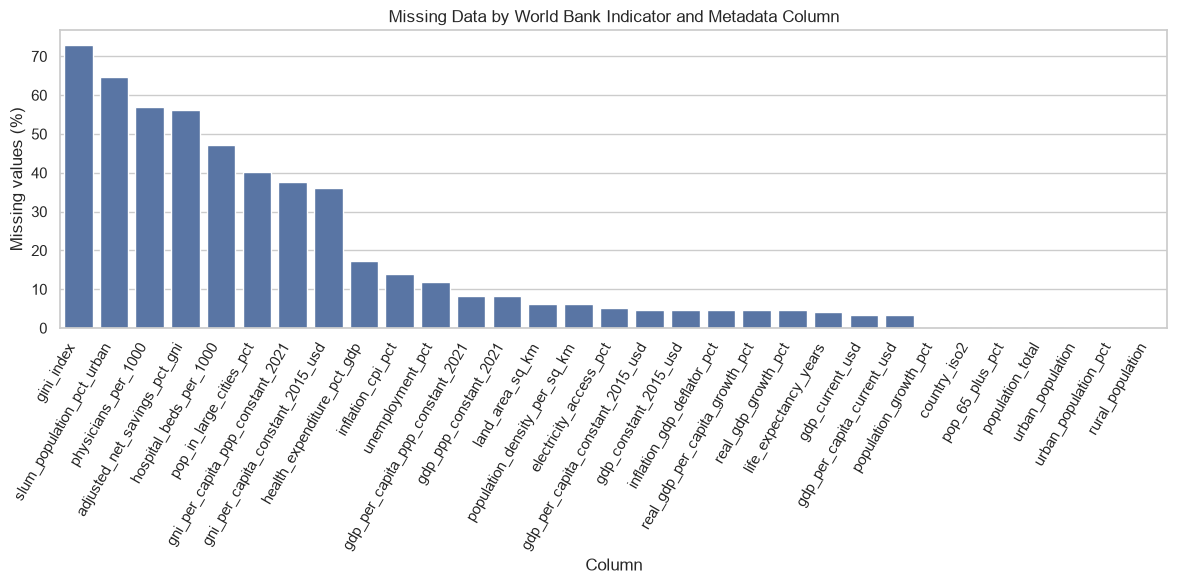

In [8]:
missing_plot = (
    missingness[missingness["missing_count"] > 0]
    .reset_index()
    .sort_values("missing_percent", ascending=False)
)

if not missing_plot.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=missing_plot,
        x="column",
        y="missing_percent"
    )

    plt.title("Missing Data by World Bank Indicator and Metadata Column")
    plt.xlabel("Column")
    plt.ylabel("Missing values (%)")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected in the dataset.")

In [9]:
# Exclude 'year' because it is the grouping variable
data_columns = [
    col for col in df_wb.columns
    if col != "year"
]

# Convert missingness into Boolean flags: True = missing
missing_flags = df_wb[data_columns].isna().copy()

# Add the corresponding year to each row
missing_flags["year"] = df_wb["year"].to_numpy()

# Year-wise percentage of missing values for each column
missing_pct_by_year = (
    missing_flags
    .groupby("year", sort=True)[data_columns]
    .mean()
    .mul(100)
    .round(2)
)

# Year-wise count of missing values for each column
missing_count_by_year = (
    missing_flags
    .groupby("year", sort=True)[data_columns]
    .sum()
    .astype(int)
)

print("Year-wise missingness (%):")
display(missing_pct_by_year)

print("Year-wise missing counts:")
display(missing_count_by_year)

Year-wise missingness (%):


,country_name,country_iso2,country_iso3,region,income_group,is_aggregate,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gni_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,gni_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population,urban_population_pct,rural_population,pop_in_large_cities_pct,land_area_sq_km,pop_65_plus_pct,gini_index,adjusted_net_savings_pct_gni,electricity_access_pct,health_expenditure_pct_gdp,unemployment_pct,physicians_per_1000,hospital_beds_per_1000,life_expectancy_years,slum_population_pct_urban
year,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2000,0.0,0.38,0.0,0.0,0.0,0.0,5.26,5.26,7.14,7.14,46.62,9.77,9.77,47.37,7.14,7.14,20.68,7.14,0.38,3.38,0.38,0.38,0.38,0.38,40.23,3.38,0.38,78.57,54.89,2.63,12.78,11.65,45.49,55.26,0.38,28.20
2001,0.0,0.38,0.0,0.0,0.0,0.0,4.89,4.89,7.14,7.14,45.49,9.77,9.77,46.24,6.77,6.77,18.80,6.77,0.38,3.38,0.38,0.38,0.38,0.38,40.23,3.38,0.38,81.95,54.51,2.63,12.78,11.65,62.03,54.89,0.38,100.00
2002,0.0,0.38,0.0,0.0,0.0,0.0,3.38,3.38,5.64,5.64,44.36,9.40,9.40,45.11,6.77,6.77,18.05,6.77,0.38,3.38,0.38,0.38,0.38,0.38,40.23,3.38,0.38,74.06,53.38,2.26,12.41,11.65,64.29,53.01,0.38,25.56
2003,0.0,0.38,0.0,0.0,0.0,0.0,3.38,3.38,5.64,5.64,44.36,9.40,9.40,45.11,5.26,5.26,16.92,5.26,0.38,3.38,0.38,0.38,0.38,0.38,40.23,3.38,0.38,73.68,52.63,2.26,11.65,11.65,63.91,51.13,0.38,100.00
2004,0.0,0.38,0.0,0.0,0.0,0.0,3.38,3.38,5.64,5.64,43.98,9.40,9.40,45.11,5.26,5.26,16.54,5.26,0.38,3.38,0.38,0.38,0.38,0.38,40.23,3.38,0.38,71.43,52.26,2.26,11.65,11.65,47.37,49.25,0.38,24.44
2005,0.0,0.38,0.0,0.0,0.0,0.0,3.38,3.38,5.64,5.64,43.23,9.40,9.40,43.98,5.26,5.26,15.41,5.26,0.38,3.38,0.38,0.38,0.38,0.38,40.23,3.38,0.38,69.55,49.62,2.26,11.65,11.65,59.40,46.99,0.38,100.00
2006,0.0,0.38,0.0,0.0,0.0,0.0,3.01,3.01,5.26,5.26,41.35,9.02,9.02,42.11,5.26,5.26,14.29,5.26,0.38,2.63,0.38,0.38,0.38,0.38,40.23,2.63,0.38,69.17,49.25,2.26,11.65,11.65,61.28,43.61,0.38,22.93
2007,0.0,0.38,0.0,0.0,0.0,0.0,3.01,3.01,4.89,4.89,40.23,8.65,8.65,40.98,4.89,4.89,13.53,4.89,0.38,2.63,0.38,0.38,0.38,0.38,40.23,2.63,0.38,72.93,47.74,1.50,11.65,11.65,57.89,45.11,0.38,100.00
2008,0.0,0.38,0.0,0.0,0.0,0.0,2.63,2.63,3.76,3.76,38.35,7.89,7.89,39.85,4.51,4.51,13.16,4.51,0.38,2.63,0.38,0.38,0.38,0.38,40.23,2.63,0.38,70.30,47.74,1.50,11.65,11.65,49.62,42.48,0.38,24.06


Year-wise missing counts:


,country_name,country_iso2,country_iso3,region,income_group,is_aggregate,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gni_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,gni_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population,urban_population_pct,rural_population,pop_in_large_cities_pct,land_area_sq_km,pop_65_plus_pct,gini_index,adjusted_net_savings_pct_gni,electricity_access_pct,health_expenditure_pct_gdp,unemployment_pct,physicians_per_1000,hospital_beds_per_1000,life_expectancy_years,slum_population_pct_urban
year,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2000,0,1,0,0,0,0,14,14,19,19,124,26,26,126,19,19,55,19,1,9,1,1,1,1,107,9,1,209,146,7,34,31,121,147,1,75
2001,0,1,0,0,0,0,13,13,19,19,121,26,26,123,18,18,50,18,1,9,1,1,1,1,107,9,1,218,145,7,34,31,165,146,1,266
2002,0,1,0,0,0,0,9,9,15,15,118,25,25,120,18,18,48,18,1,9,1,1,1,1,107,9,1,197,142,6,33,31,171,141,1,68
2003,0,1,0,0,0,0,9,9,15,15,118,25,25,120,14,14,45,14,1,9,1,1,1,1,107,9,1,196,140,6,31,31,170,136,1,266
2004,0,1,0,0,0,0,9,9,15,15,117,25,25,120,14,14,44,14,1,9,1,1,1,1,107,9,1,190,139,6,31,31,126,131,1,65
2005,0,1,0,0,0,0,9,9,15,15,115,25,25,117,14,14,41,14,1,9,1,1,1,1,107,9,1,185,132,6,31,31,158,125,1,266
2006,0,1,0,0,0,0,8,8,14,14,110,24,24,112,14,14,38,14,1,7,1,1,1,1,107,7,1,184,131,6,31,31,163,116,1,61
2007,0,1,0,0,0,0,8,8,13,13,107,23,23,109,13,13,36,13,1,7,1,1,1,1,107,7,1,194,127,4,31,31,154,120,1,266
2008,0,1,0,0,0,0,7,7,10,10,102,21,21,106,12,12,35,12,1,7,1,1,1,1,107,7,1,187,127,4,31,31,132,113,1,64


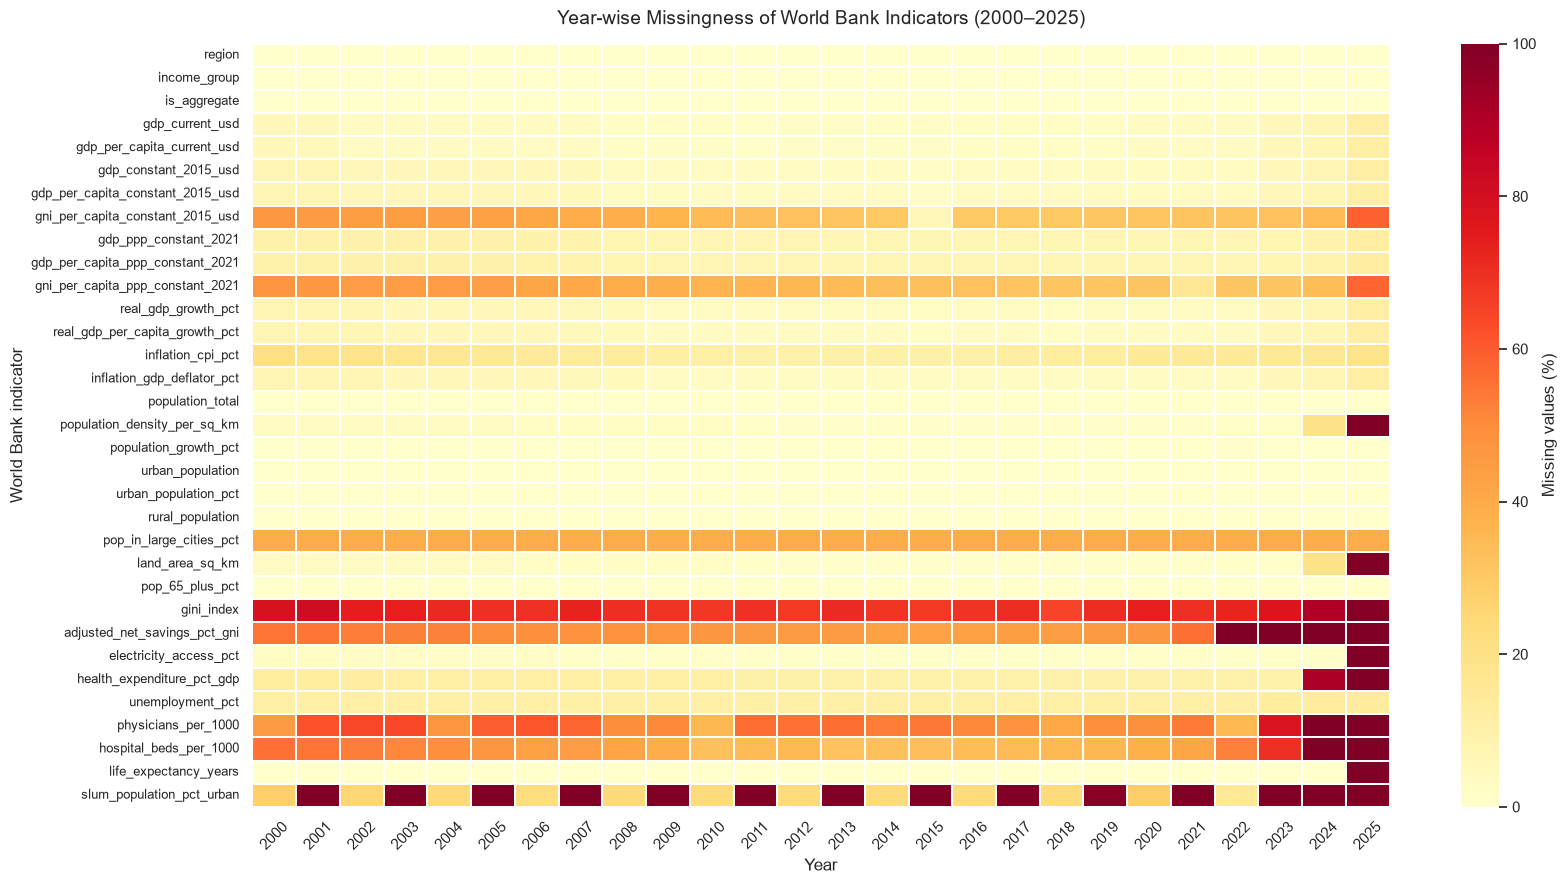

In [10]:
# Exclude identifiers and the year column from the indicator heatmap
metadata_cols = {
    "year",
    "country_name",
    "country_iso2",
    "country_iso3"
}

indicator_cols = [
    col for col in missing_pct_by_year.columns
    if col not in metadata_cols
]

plt.figure(figsize=(17, 9))

sns.heatmap(
    missing_pct_by_year[indicator_cols].T,
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.2,
    cbar_kws={"label": "Missing values (%)"}
)

plt.title(
    "Year-wise Missingness of World Bank Indicators (2000–2025)",
    fontsize=14,
    pad=14
)
plt.xlabel("Year")
plt.ylabel("World Bank indicator")
plt.xticks(rotation=45)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

In [11]:
indicators_2021 = [
    "gdp_ppp_constant_2021",
    "gdp_per_capita_ppp_constant_2021",
    "gni_per_capita_ppp_constant_2021"
]

# Keep only indicators present in the dataset
indicators_2021 = [
    col for col in indicators_2021
    if col in df_wb.columns
]

missing_2021_summary = pd.DataFrame({
    "missing_count": df_wb[indicators_2021].isna().sum(),
    "missing_percent": df_wb[indicators_2021].isna().mean() * 100,
    "available_count": df_wb[indicators_2021].notna().sum()
}).sort_values("missing_percent", ascending=False)

display(missing_2021_summary.round(2))

,missing_count,missing_percent,available_count
gni_per_capita_ppp_constant_2021,2595,37.52,4321
gdp_ppp_constant_2021,567,8.20,6349
gdp_per_capita_ppp_constant_2021,567,8.20,6349


In [12]:
# Work on a copy so the original dataset remains unchanged
growth_df = df_wb.copy()

growth_df["_year"] = pd.to_numeric(
    growth_df["year"], errors="coerce"
)

# Entity identifier used to calculate each entity's year-on-year change
entity_col = (
    "country_iso3"
    if "country_iso3" in growth_df.columns
    else "country_name"
)

# Official annual rate columns already in the dataset
reported_rates = {
    "Real GDP growth (%)": "real_gdp_growth_percent",
    "Real GDP per capita growth (%)": "real_gdp_per_capita_growth_percent",
    "Population growth (%)": "population_growth_annual_percent",
    "Consumer price inflation (%)": "consumer_price_inflation_annual_percent",
}

median_series = {}
count_series = {}

# Median and coverage for reported annual rates
for label, col in reported_rates.items():
    if col not in growth_df.columns:
        print(f"Not found; skipping: {col}")
        continue

    temp = growth_df[["_year", col]].copy()
    temp[col] = pd.to_numeric(temp[col], errors="coerce")
    grouped = temp.groupby("_year")[col]

    median_series[label] = grouped.median()
    count_series[label] = grouped.count()


# Find a constant-2021 PPP GDP level column, if present
def find_ppp_level(per_capita=False):
    candidates = []

    for col in growth_df.columns:
        name = col.lower()

        if "gdp" not in name or "ppp" not in name:
            continue
        if "growth" in name or "percent" in name:
            continue
        if per_capita and "capita" not in name:
            continue
        if not per_capita and "capita" in name:
            continue

        candidates.append(col)

    # Prefer columns explicitly labelled with 2021
    candidates_2021 = [
        col for col in candidates if "2021" in col.lower()
    ]

    if len(candidates_2021) == 1:
        return candidates_2021[0]
    if len(candidates) == 1:
        return candidates[0]

    print(
        "PPP level columns requiring review "
        f"({'per capita' if per_capita else 'total GDP'}):",
        candidates
    )
    return None


ppp_columns = {
    "GDP PPP": find_ppp_level(per_capita=False),
    "GDP per capita PPP": find_ppp_level(per_capita=True),
}

print("PPP columns selected:", ppp_columns)


# Derive year-on-year growth from each selected PPP level series
for label, col in ppp_columns.items():
    if col is None:
        continue

    temp = growth_df[[entity_col, "_year", col]].copy()
    temp[col] = pd.to_numeric(temp[col], errors="coerce")
    temp = temp.dropna(subset=[entity_col, "_year"])
    temp = temp.sort_values([entity_col, "_year"])

    grouped = temp.groupby(entity_col, sort=False)
    previous_value = grouped[col].shift(1)
    previous_year = grouped["_year"].shift(1)

    annual_growth = (
        (temp[col] / previous_value) - 1
    ) * 100

    # Only compare consecutive years with valid, non-zero prior values
    valid = (
        (temp["_year"] - previous_year == 1)
        & previous_value.notna()
        & (previous_value != 0)
        & temp[col].notna()
    )

    temp["_annual_growth"] = annual_growth.where(valid)

    yearly = temp.groupby("_year")["_annual_growth"]

    median_series[f"Derived {label} growth (%)"] = yearly.median()
    count_series[f"Derived {label} growth (%)"] = yearly.count()


# Display annual medians and the number of observations behind them
median_growth_by_year = (
    pd.DataFrame(median_series)
    .sort_index()
    .round(2)
)

growth_observations_by_year = (
    pd.DataFrame(count_series)
    .reindex(median_growth_by_year.index)
    .fillna(0)
    .astype(int)
)

print("Median annual rates (%):")
display(median_growth_by_year)

print("Number of available observations behind each median:")
display(growth_observations_by_year)

Not found; skipping: real_gdp_growth_percent
Not found; skipping: real_gdp_per_capita_growth_percent
Not found; skipping: population_growth_annual_percent
Not found; skipping: consumer_price_inflation_annual_percent
PPP columns selected: {'GDP PPP': 'gdp_ppp_constant_2021', 'GDP per capita PPP': 'gdp_per_capita_ppp_constant_2021'}
Median annual rates (%):


,Derived GDP PPP growth (%),Derived GDP per capita PPP growth (%)
_year,,
2000,NaN,NaN
2001,3.10,1.69
2002,3.73,1.93
2003,4.25,2.75
2004,5.33,3.84
2005,4.99,3.27
2006,5.67,3.88
2007,5.75,3.77
2008,4.04,2.23


Number of available observations behind each median:


,Derived GDP PPP growth (%),Derived GDP per capita PPP growth (%)
_year,,
2000,0,0
2001,240,240
2002,240,240
2003,241,241
2004,241,241
2005,241,241
2006,241,241
2007,242,242
2008,243,243


In [13]:
gdp_pc_col = "gdp_per_capita_ppp_constant_2021"

# Work on a separate copy; do not modify df_wb
gdp_eda = df_wb[["year", gdp_pc_col]].copy()

# Exclude known World Bank aggregates, if the flag is available
if "is_aggregate" in df_wb.columns:
    is_aggregate = (
        df_wb["is_aggregate"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )

    gdp_eda = gdp_eda.loc[~is_aggregate].copy()

# Ensure year and GDP per capita are numeric
gdp_eda["year"] = pd.to_numeric(
    gdp_eda["year"], errors="coerce"
)
gdp_eda[gdp_pc_col] = pd.to_numeric(
    gdp_eda[gdp_pc_col], errors="coerce"
)

# Exclude invalid years and missing GDP observations for this analysis only
gdp_eda = gdp_eda.dropna(subset=["year", gdp_pc_col])

# Calculate annual distribution statistics
gdp_pc_summary = (
    gdp_eda.groupby("year")[gdp_pc_col]
    .agg(
        entities_with_value="count",
        q25=lambda x: x.quantile(0.25),
        median="median",
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

gdp_pc_summary["IQR"] = (
    gdp_pc_summary["q75"] - gdp_pc_summary["q25"]
)

gdp_pc_summary["year"] = gdp_pc_summary["year"].astype(int)

display(gdp_pc_summary.round(2))

,year,entities_with_value,q25,median,q75,IQR
0,2000,192,3818.61,10588.78,23097.94,19279.33
1,2001,192,3906.07,10907.29,23305.60,19399.54
2,2002,193,3942.76,11144.05,24229.30,20286.53
3,2003,193,3998.44,11183.29,25485.16,21486.73
4,2004,193,4088.98,11607.94,28225.99,24137.01
5,2005,193,4152.32,12022.51,31302.96,27150.64
6,2006,194,4240.51,12982.80,33345.28,29104.77
7,2007,195,4359.20,13754.92,35261.07,30901.87
8,2008,197,4446.41,14030.14,35825.33,31378.92
9,2009,198,4698.60,13655.27,34859.08,30160.48


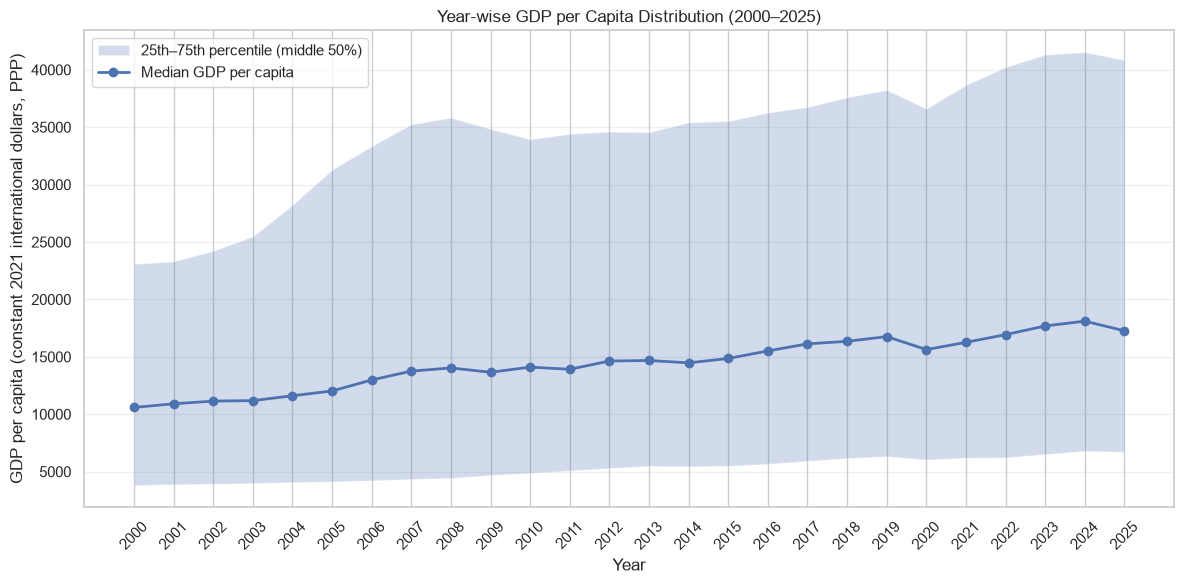

In [14]:
plt.figure(figsize=(12, 6))

plt.fill_between(
    gdp_pc_summary["year"],
    gdp_pc_summary["q25"],
    gdp_pc_summary["q75"],
    alpha=0.25,
    label="25th–75th percentile (middle 50%)"
)

plt.plot(
    gdp_pc_summary["year"],
    gdp_pc_summary["median"],
    marker="o",
    linewidth=2,
    label="Median GDP per capita"
)

plt.title(
    "Year-wise GDP per Capita Distribution (2000–2025)"
)
plt.xlabel("Year")
plt.ylabel("GDP per capita (constant 2021 international dollars, PPP)")
plt.xticks(gdp_pc_summary["year"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# GDP-per-capita metrics to examine next
gdp_measures = {
    "Nominal GDP per capita (current US$)": "gdp_per_capita_current_usd",
    "Real GDP per capita (constant 2015 US$)": "gdp_per_capita_constant_2015_usd",
}

# Copy the data so the original DataFrame remains unchanged
gdp_eda_next = df_wb.copy()

# Exclude known World Bank aggregates, if the flag is available
if "is_aggregate" in gdp_eda_next.columns:
    aggregate_flag = (
        gdp_eda_next["is_aggregate"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )

    gdp_eda_next = gdp_eda_next.loc[~aggregate_flag].copy()

# Convert year to numeric
gdp_eda_next["year"] = pd.to_numeric(
    gdp_eda_next["year"], errors="coerce"
)

gdp_summaries = {}

for label, col in gdp_measures.items():

    if col not in gdp_eda_next.columns:
        print(f"Column not found; skipping: {col}")
        continue

    temp = gdp_eda_next[["year", col]].copy()
    temp[col] = pd.to_numeric(temp[col], errors="coerce")
    temp = temp.dropna(subset=["year"])

    # Calculate the distribution for each year
    summary = (
        temp.groupby("year")[col]
        .agg(
            n="count",
            q25=lambda x: x.quantile(0.25),
            median="median",
            q75=lambda x: x.quantile(0.75),
        )
        .sort_index()
    )

    summary["iqr"] = summary["q75"] - summary["q25"]
    gdp_summaries[label] = summary

    print(f"\n{label}")
    display(summary.round(2))

# Combined summary for later reference
gdp_summary_two_metrics = pd.concat(
    gdp_summaries,
    names=["measure", "year"]
)

print("Combined GDP-per-capita summary:")
display(gdp_summary_two_metrics.round(2))


Nominal GDP per capita (current US$)


,n,q25,median,q75,iqr
year,,,,,
2000,204,635.43,1985.55,11554.33,10918.90
2001,205,659.59,1929.57,11539.18,10879.59
2002,209,743.01,2136.57,12936.69,12193.68
2003,209,817.89,2569.25,14711.67,13893.79
2004,209,962.48,3067.42,16671.34,15708.86
2005,209,1084.07,3577.36,17032.34,15948.27
2006,210,1232.37,4192.56,18841.37,17609.00
2007,210,1375.60,4752.70,20542.35,19166.74
2008,211,1604.38,5377.41,22590.17,20985.79



Real GDP per capita (constant 2015 US$)


,n,q25,median,q75,iqr
year,,,,,
2000,199,1371.96,3866.69,16053.61,14681.64
2001,199,1434.94,3937.90,15790.08,14355.14
2002,203,1490.67,4086.10,18175.27,16684.60
2003,203,1500.69,4162.67,18310.98,16810.29
2004,203,1554.31,4311.92,18781.55,17227.24
2005,203,1620.99,4549.25,19177.00,17556.00
2006,204,1700.76,4742.89,20113.93,18413.17
2007,205,1830.23,4947.25,20770.27,18940.04
2008,208,1928.32,5046.88,21275.18,19346.86


Combined GDP-per-capita summary:


n      q25   median       q75       iqr
measure                                 year                                           
Nominal GDP per capita (current US$)    2000  204   635.43  1985.55  11554.33  10918.90
                                        2001  205   659.59  1929.57  11539.18  10879.59
                                        2002  209   743.01  2136.57  12936.69  12193.68
                                        2003  209   817.89  2569.25  14711.67  13893.79
                                        2004  209   962.48  3067.42  16671.34  15708.86
                                        2005  209  1084.07  3577.36  17032.34  15948.27
                                        2006  210  1232.37  4192.56  18841.37  17609.00
                                        2007  210  1375.60  4752.70  20542.35  19166.74
                                        2008  211  1604.38  5377.41  22590.17  20985.79
                                        2009  213  1540.45  5089.24  20655.92  19115.46
                                        2010  213  1685.15  5843.53  22494.81  20809.66
                                        2011  214  1981.61  6527.67  24584.71  22603.11
                                        2012  212  2111.09  6574.01  22551.18  20440.09
                                        2013  212  2261.44  7056.44  23292.23  21030.79
                                        2014  213  2214.62  7146.70  23160.65  20946.03
                                        2015  212  2233.66  6147.91  20496.42  18262.77
                                        2016  211  2145.07  5982.37  21857.78  19712.71
                                        2017  211  2404.06  6548.04  23616.18  21212.13
                                        2018  211  2474.67  6978.49  26106.23  23631.55
                                        2019  211  2515.49  7037.01  25155.42  22639.93
                                        2020  210  2263.54  6433.08  23270.76  21007.22
                                        2021  210  2609.39  7268.90  27283.92  24674.53
                                        2022  209  2899.16  7655.59  28360.30  25461.14
                                        2023  204  2945.93  7862.03  30638.40  27692.48
                                        2024  200  2817.88  7852.45  29397.17  26579.29
                                        2025  186  3057.82  7882.45  26789.00  23731.18
Real GDP per capita (constant 2015 US$) 2000  199  1371.96  3866.69  16053.61  14681.64
                                        2001  199  1434.94  3937.90  15790.08  14355.14
                                        2002  203  1490.67  4086.10  18175.27  16684.60
                                        2003  203  1500.69  4162.67  18310.98  16810.29
                                        2004  203  1554.31  4311.92  18781.55  17227.24
                                        2005  203  1620.99  4549.25  19177.00  17556.00
                                        2006  204  1700.76  4742.89  20113.93  18413.17
                                        2007  205  1830.23  4947.25  20770.27  18940.04
                                        2008  208  1928.32  5046.88  21275.18  19346.86
                                        2009  210  2021.51  5190.09  20558.10  18536.59
                                        2010  210  2116.48  5442.31  20739.59  18623.11
                                        2011  210  2109.53  5627.05  20531.09  18421.56
                                        2012  209  2139.48  5742.92  19894.87  17755.39
                                        2013  210  2145.63  6017.27  19626.21  17480.58
                                        2014  210  2235.22  6119.17  20148.99  17913.77
                                        2015  212  2233.66  6147.91  20496.42  18262.77
                                        2016  209  2234.76  6095.30  21133.66  18898.90
                                        2017  209  2351.57  6243.13  21191.60  18840.03


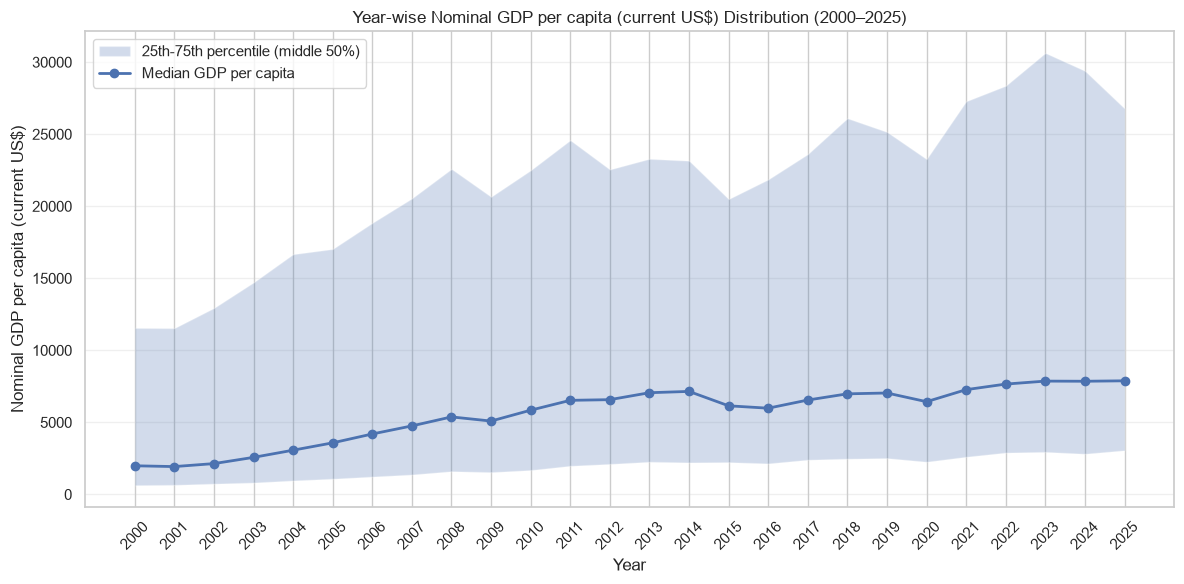

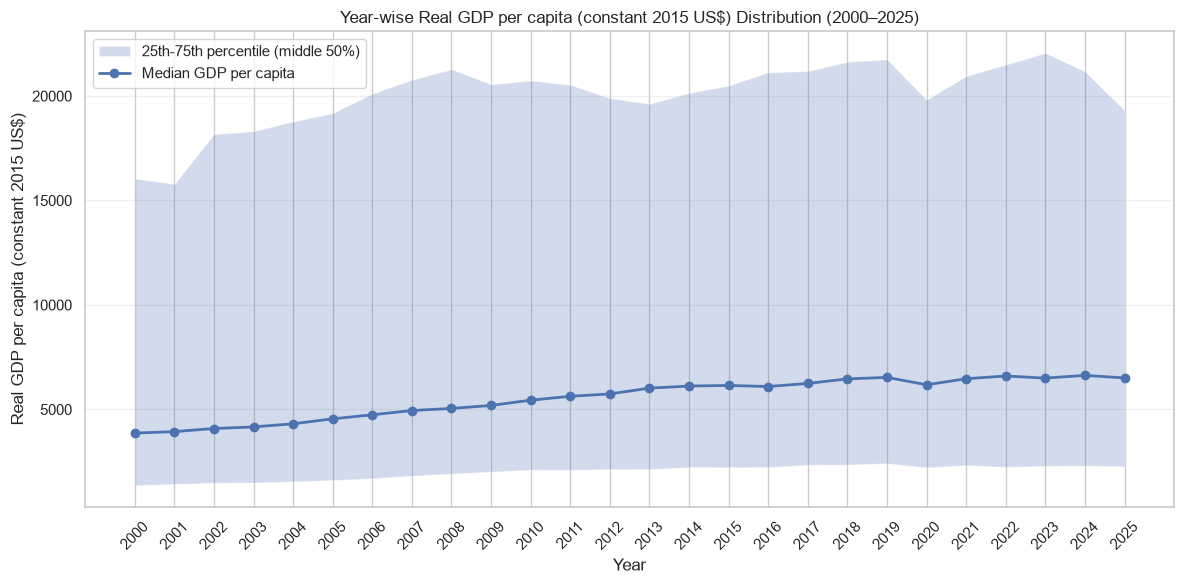

In [16]:
for label, summary in gdp_summaries.items():

    years = summary.index.to_numpy(dtype=float)
    q25 = summary["q25"].to_numpy(dtype=float)
    median = summary["median"].to_numpy(dtype=float)
    q75 = summary["q75"].to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.fill_between(
        years,
        q25,
        q75,
        alpha=0.25,
        label="25th-75th percentile (middle 50%)"
    )

    ax.plot(
        years,
        median,
        marker="o",
        linewidth=2,
        label="Median GDP per capita"
    )

    ax.set_title(f"Year-wise {label} Distribution (2000–2025)")
    ax.set_xlabel("Year")
    ax.set_ylabel(label)
    ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()

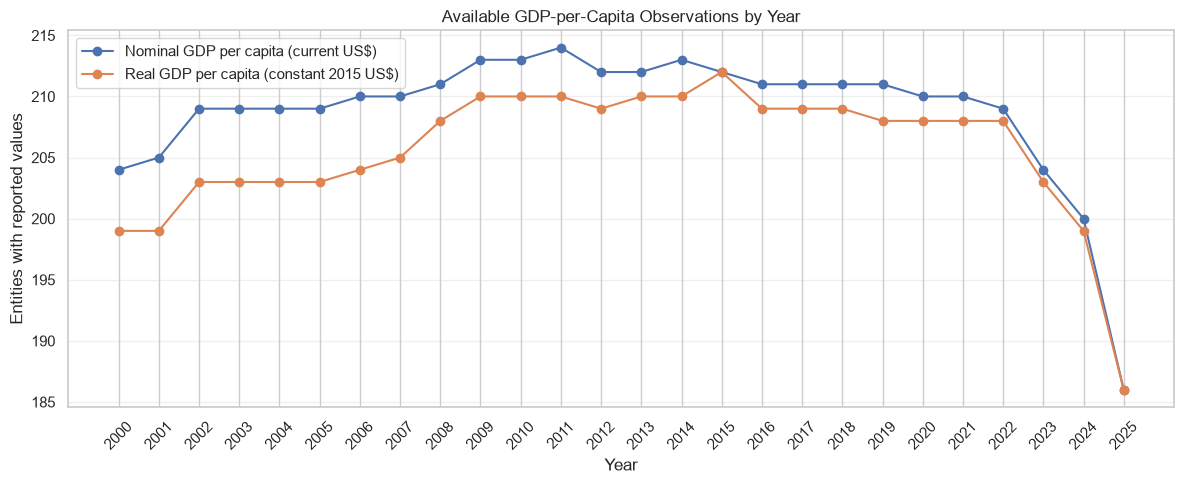

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))

for label, summary in gdp_summaries.items():
    ax.plot(
        summary.index,
        summary["n"],
        marker="o",
        label=label
    )

ax.set_title("Available GDP-per-Capita Observations by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Entities with reported values")
ax.set_xticks(sorted({
    year
    for summary in gdp_summaries.values()
    for year in summary.index
}))
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
# Core economic and demographic indicators for the first correlation analysis
candidate_cols = [
    "gdp_current_usd",
    "gdp_per_capita_current_usd",
    "gdp_constant_2015_usd",
    "gdp_per_capita_constant_2015_usd",
    "gdp_ppp_constant_2021",
    "gdp_per_capita_ppp_constant_2021",
    "real_gdp_growth_pct",
    "real_gdp_per_capita_growth_pct",
    "inflation_cpi_pct",
    "inflation_gdp_deflator_pct",
    "population_total",
    "population_density_per_sq_km",
    "population_growth_pct",
    "urban_population_pct",
    "unemployment_pct",
]

# Work from a copy
corr_source = df_wb.copy()

# Remove flagged aggregates, if the column exists
if "is_aggregate" in corr_source.columns:
    aggregate_flag = (
        corr_source["is_aggregate"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes"])
    )

    corr_source = corr_source.loc[~aggregate_flag].copy()

# Use only columns available in this dataset
available_cols = [
    col for col in candidate_cols
    if col in corr_source.columns
]

missing_cols = [
    col for col in candidate_cols
    if col not in corr_source.columns
]

if missing_cols:
    print("Columns not found:", missing_cols)

# Convert selected indicators to numeric
corr_data = corr_source[available_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Treat infinite values as missing
corr_data = corr_data.replace([np.inf, -np.inf], np.nan)

# Inspect data coverage before calculating correlations
coverage = pd.DataFrame({
    "valid_count": corr_data.notna().sum(),
    "missing_count": corr_data.isna().sum(),
    "missing_percent": corr_data.isna().mean() * 100,
}).sort_values("missing_percent")

display(coverage.round(2))

,valid_count,missing_count,missing_percent
urban_population_pct,5642,0,0.00
population_total,5642,0,0.00
population_growth_pct,5641,1,0.02
gdp_current_usd,5428,214,3.79
gdp_per_capita_current_usd,5428,214,3.79
real_gdp_growth_pct,5354,288,5.10
real_gdp_per_capita_growth_pct,5354,288,5.10
inflation_gdp_deflator_pct,5347,295,5.23
gdp_constant_2015_usd,5345,297,5.26
gdp_per_capita_constant_2015_usd,5345,297,5.26


In [19]:
MAX_MISSING_PERCENT = 25

selected_cols = coverage.index[
    coverage["missing_percent"] <= MAX_MISSING_PERCENT
].tolist()

excluded_cols = coverage.index[
    coverage["missing_percent"] > MAX_MISSING_PERCENT
].tolist()

print("Indicators retained for correlation:")
print(selected_cols)

print("\nExcluded due to missingness:")
print(excluded_cols)

corr_data = corr_data[selected_cols]

Indicators retained for correlation:
['urban_population_pct', 'population_total', 'population_growth_pct', 'gdp_current_usd', 'gdp_per_capita_current_usd', 'real_gdp_growth_pct', 'real_gdp_per_capita_growth_pct', 'inflation_gdp_deflator_pct', 'gdp_constant_2015_usd', 'gdp_per_capita_constant_2015_usd', 'population_density_per_sq_km', 'gdp_per_capita_ppp_constant_2021', 'gdp_ppp_constant_2021', 'unemployment_pct', 'inflation_cpi_pct']

Excluded due to missingness:
[]


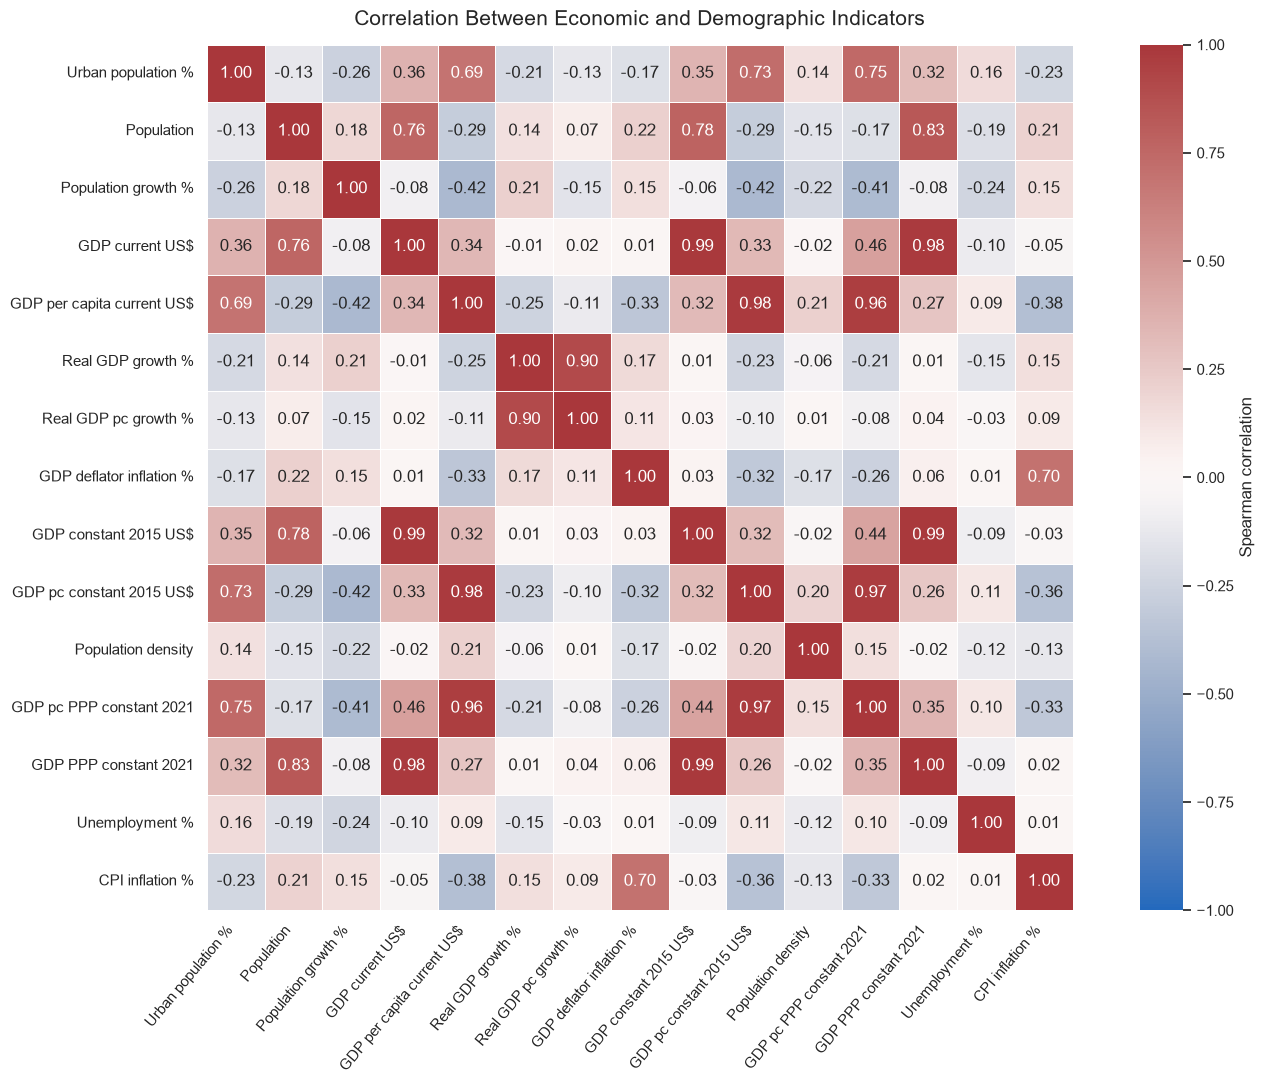

In [20]:
# Calculate pairwise Spearman correlations
corr_matrix = corr_data.corr(
    method="spearman",
    min_periods=30
)

# More readable labels for presentation
display_names = {
    "gdp_current_usd": "GDP current US$",
    "gdp_per_capita_current_usd": "GDP per capita current US$",
    "gdp_constant_2015_usd": "GDP constant 2015 US$",
    "gdp_per_capita_constant_2015_usd": "GDP pc constant 2015 US$",
    "gdp_ppp_constant_2021": "GDP PPP constant 2021",
    "gdp_per_capita_ppp_constant_2021": "GDP pc PPP constant 2021",
    "real_gdp_growth_pct": "Real GDP growth %",
    "real_gdp_per_capita_growth_pct": "Real GDP pc growth %",
    "inflation_cpi_pct": "CPI inflation %",
    "inflation_gdp_deflator_pct": "GDP deflator inflation %",
    "population_total": "Population",
    "population_density_per_sq_km": "Population density",
    "population_growth_pct": "Population growth %",
    "urban_population_pct": "Urban population %",
    "unemployment_pct": "Unemployment %",
}

corr_matrix = corr_matrix.rename(
    index=display_names,
    columns=display_names
)

plt.figure(figsize=(15, 11))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.4,
    square=True,
    cbar_kws={"label": "Spearman correlation"}
)

plt.title(
    "Correlation Between Economic and Demographic Indicators",
    fontsize=15,
    pad=14
)
plt.xticks(rotation=50, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
# Work on a copy; do not modify df_wb
gdp_trend = df_wb.copy()

START_YEAR = 2000
END_YEAR = 2024
RANKING_YEAR = 2024

GDP_METRICS = {
    "Nominal GDP (current US$)": "gdp_current_usd",
    "Real GDP (constant 2021 international $, PPP)": "gdp_ppp_constant_2021",
}

# Select entity identifier and display-name columns
entity_col = (
    "country_iso3"
    if "country_iso3" in gdp_trend.columns
    else "country_name"
)
name_col = (
    "country_name"
    if "country_name" in gdp_trend.columns
    else entity_col
)

# Remove explicitly marked World Bank aggregates
if "is_aggregate" in gdp_trend.columns:
    aggregate_flag = (
        gdp_trend["is_aggregate"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes", "y"])
    )
    gdp_trend = gdp_trend.loc[~aggregate_flag].copy()

# Standardise types and limit the analysis period
gdp_trend["year"] = pd.to_numeric(
    gdp_trend["year"], errors="coerce"
)

gdp_trend = gdp_trend.loc[
    gdp_trend["year"].between(START_YEAR, END_YEAR)
].copy()

for col in GDP_METRICS.values():
    if col in gdp_trend.columns:
        gdp_trend[col] = pd.to_numeric(
            gdp_trend[col], errors="coerce"
        )

# Rank entities separately for each GDP measure
top_entities = {}

for label, metric in GDP_METRICS.items():

    if metric not in gdp_trend.columns:
        print(f"Column not found: {metric}")
        continue

    ranking = (
        gdp_trend.loc[
            gdp_trend["year"].eq(RANKING_YEAR)
        ]
        .dropna(subset=[entity_col, metric])
        .sort_values(metric, ascending=False)
        .drop_duplicates(subset=[entity_col])
        .head(10)
        [[entity_col, name_col, "region", metric]]
    )

    top_entities[metric] = ranking[entity_col].tolist()

    print(f"\nTop 10 by {label} in {RANKING_YEAR}")
    display(ranking.style.format({metric: "{:,.0f}"}))


Top 10 by Nominal GDP (current US$) in 2024


,country_iso3,country_name,region,gdp_current_usd
6637,USA,United States,North America,"29,298,013,000,000"
6430,CHN,China,East Asia & Pacific,"18,729,668,435,848"
6472,DEU,Germany,Europe & Central Asia,"4,685,592,577,805"
6504,JPN,Japan,East Asia & Pacific,"4,190,008,188,359"
6495,IND,India,South Asia,"3,760,813,470,501"
6636,GBR,United Kingdom,Europe & Central Asia,"3,695,539,513,534"
6467,FRA,France,Europe & Central Asia,"3,160,442,622,465"
6502,ITA,Italy,Europe & Central Asia,"2,383,435,562,458"
6422,CAN,Canada,North America,"2,270,076,189,683"
6586,RUS,Russian Federation,Europe & Central Asia,"2,186,462,268,813"



Top 10 by Real GDP (constant 2021 international $, PPP) in 2024


,country_iso3,country_name,region,gdp_ppp_constant_2021
6430,CHN,China,East Asia & Pacific,"33,592,044,935,159"
6637,USA,United States,North America,"25,737,667,720,037"
6495,IND,India,South Asia,"13,662,085,943,277"
6586,RUS,Russian Federation,Europe & Central Asia,"6,121,781,512,040"
6504,JPN,Japan,East Asia & Pacific,"5,886,331,380,867"
6472,DEU,Germany,Europe & Central Asia,"5,232,698,916,861"
6413,BRA,Brazil,Latin America & Caribbean,"4,166,273,441,899"
6496,IDN,Indonesia,East Asia & Pacific,"4,102,273,900,421"
6467,FRA,France,Europe & Central Asia,"3,756,585,907,158"
6636,GBR,United Kingdom,Europe & Central Asia,"3,700,441,255,614"


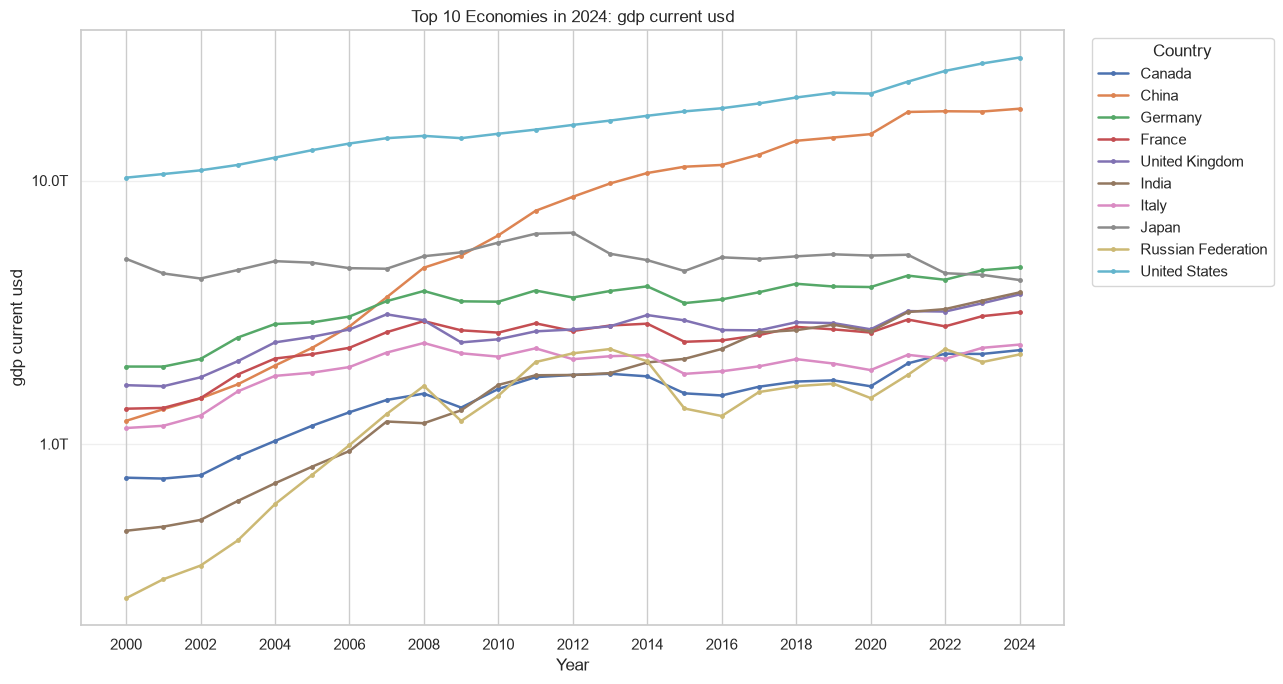

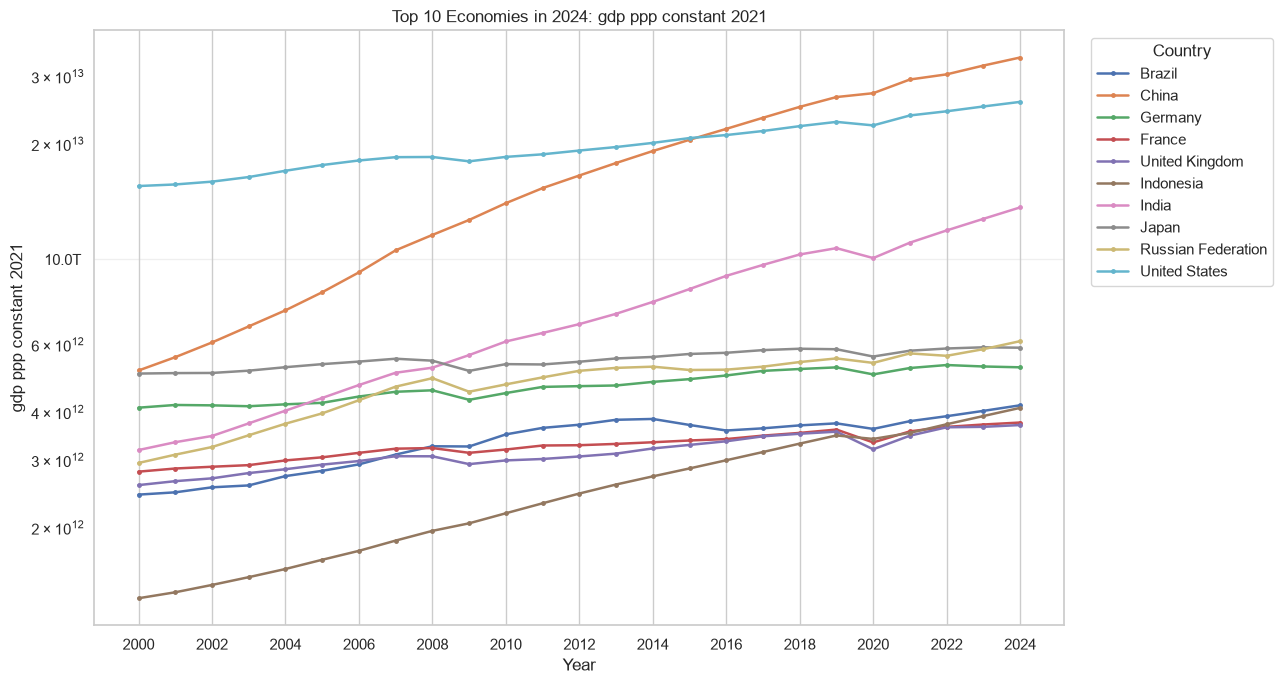

In [22]:
from matplotlib.ticker import FuncFormatter

def compact_money(x, pos):
    if abs(x) >= 1e12:
        return f"{x / 1e12:.1f}T"
    if abs(x) >= 1e9:
        return f"{x / 1e9:.0f}B"
    return f"{x:,.0f}"


for metric, entity_ids in top_entities.items():

    if not entity_ids:
        continue

    plot_df = gdp_trend.loc[
        gdp_trend[entity_col].isin(entity_ids)
    ].dropna(subset=[metric]).copy()

    fig, ax = plt.subplots(figsize=(13, 7))

    for entity_id, group in plot_df.groupby(entity_col):
        group = group.sort_values("year")
        country_name = str(group[name_col].iloc[0])

        ax.plot(
            group["year"],
            group[metric],
            marker="o",
            markersize=2.5,
            linewidth=1.8,
            label=country_name
        )

    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(compact_money))

    ax.set_title(
        f"Top 10 Economies in {RANKING_YEAR}: "
        f"{metric.replace('_', ' ')}"
    )
    ax.set_xlabel("Year")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_xticks(range(START_YEAR, END_YEAR + 1, 2))
    ax.grid(axis="y", alpha=0.3)
    ax.legend(
        title="Country",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

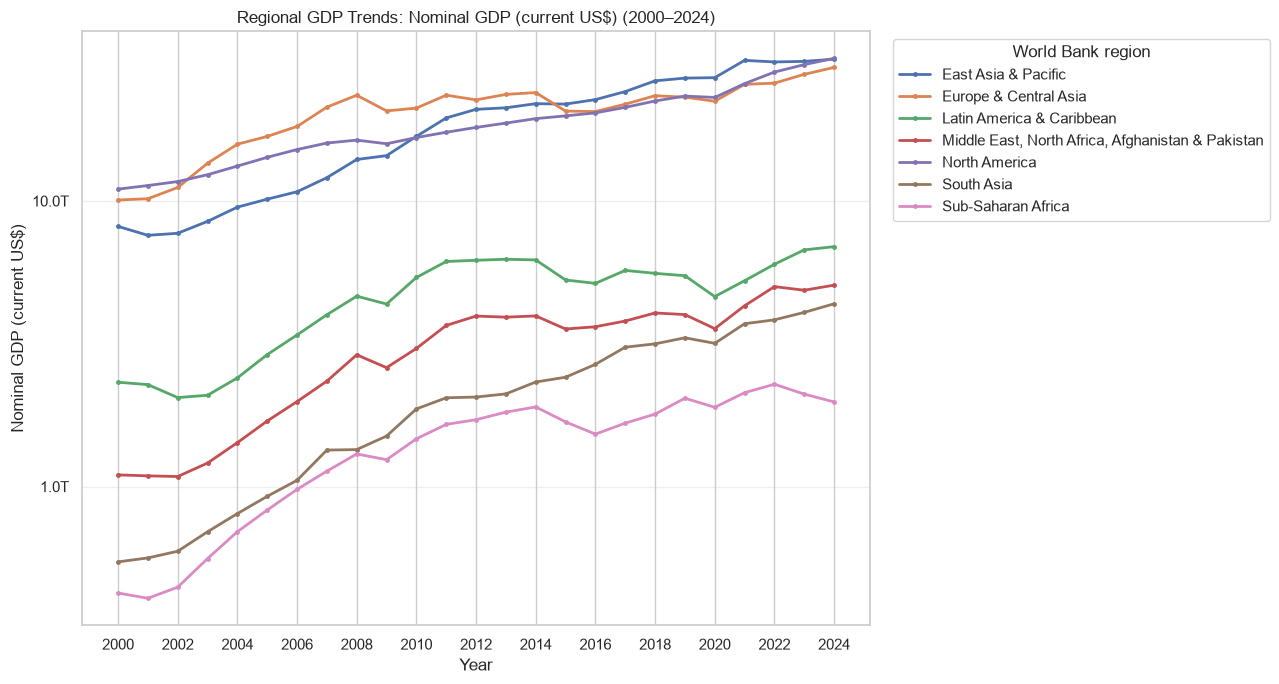

Available entity counts by region in 2024:


,region,entities_with_values
168,East Asia & Pacific,33
169,Europe & Central Asia,53
170,Latin America & Caribbean,38
171,"Middle East, North Africa, Afghanistan & Pakistan",21
172,North America,3
173,South Asia,6
174,Sub-Saharan Africa,46


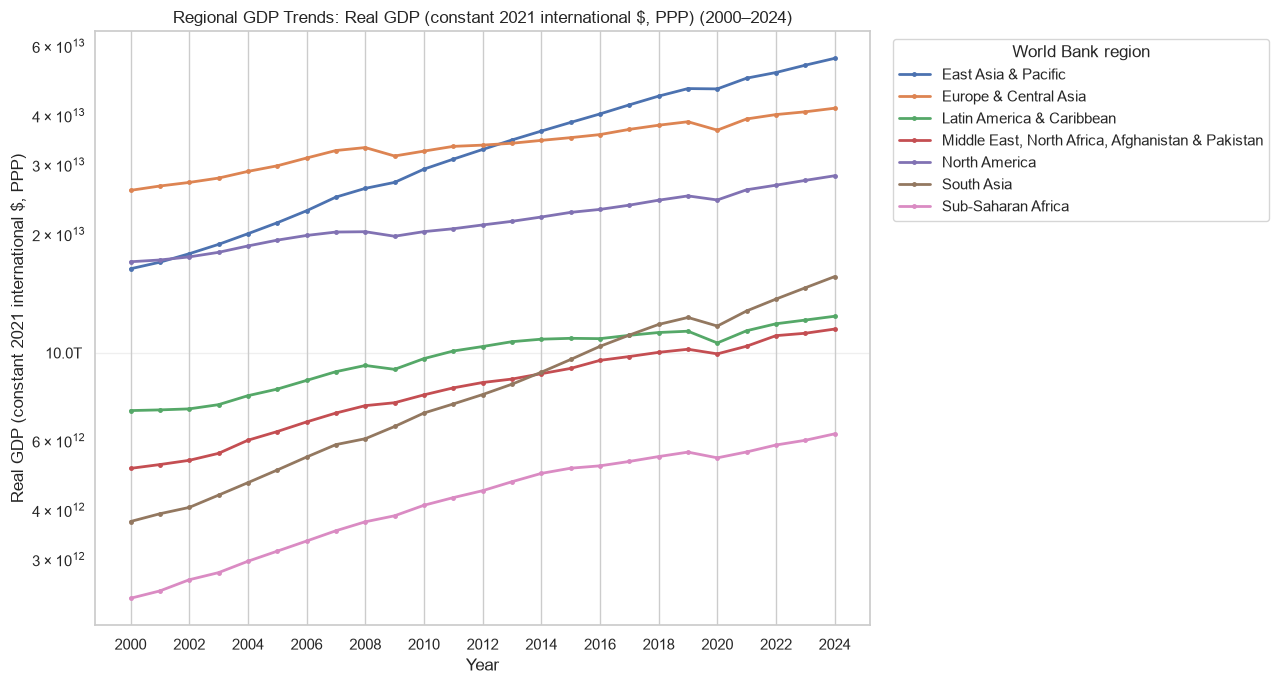

Available entity counts by region in 2024:


,region,entities_with_values
168,East Asia & Pacific,31
169,Europe & Central Asia,51
170,Latin America & Caribbean,37
171,"Middle East, North Africa, Afghanistan & Pakistan",21
172,North America,3
173,South Asia,6
174,Sub-Saharan Africa,46


In [23]:
if "region" not in gdp_trend.columns:
    print("The region column is unavailable.")
else:
    regional_data = gdp_trend.copy()

    regional_data["region"] = (
        regional_data["region"]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

    regional_data = regional_data.dropna(subset=["region"])

    for label, metric in GDP_METRICS.items():

        if metric not in regional_data.columns:
            continue

        regional_totals = (
            regional_data
            .groupby(["year", "region"], as_index=False)
            .agg(
                regional_gdp=(
                    metric,
                    lambda values: values.sum(min_count=1)
                ),
                entities_with_values=(metric, "count")
            )
        )

        fig, ax = plt.subplots(figsize=(13, 7))

        for region, group in regional_totals.groupby("region"):
            group = group.sort_values("year")

            ax.plot(
                group["year"],
                group["regional_gdp"],
                marker="o",
                markersize=2.5,
                linewidth=2,
                label=region
            )

        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(FuncFormatter(compact_money))

        ax.set_title(f"Regional GDP Trends: {label} (2000–2024)")
        ax.set_xlabel("Year")
        ax.set_ylabel(label)
        ax.set_xticks(range(START_YEAR, END_YEAR + 1, 2))
        ax.grid(axis="y", alpha=0.3)
        ax.legend(
            title="World Bank region",
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )

        plt.tight_layout()
        plt.show()

        print(f"Available entity counts by region in {RANKING_YEAR}:")
        display(
            regional_totals.loc[
                regional_totals["year"].eq(RANKING_YEAR),
                ["region", "entities_with_values"]
            ].sort_values("region")
        )

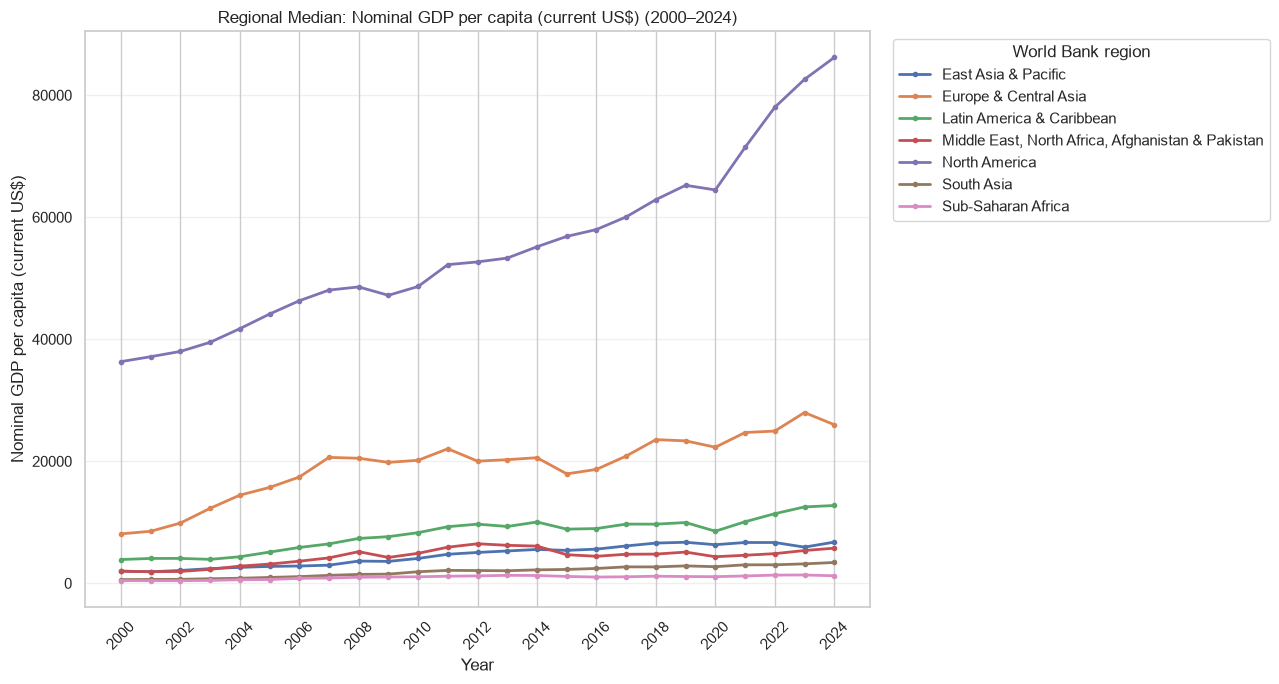

Regional summary and coverage: Nominal GDP per capita (current US$)


,year,region,median,q25,q75,entities_with_values
0,2000,East Asia & Pacific,1995.72,845.37,13641.10,33
7,2001,East Asia & Pacific,1889.93,732.31,13882.86,33
14,2002,East Asia & Pacific,2101.61,863.28,16282.16,36
21,2003,East Asia & Pacific,2405.41,1025.55,19099.88,36
28,2004,East Asia & Pacific,2603.82,1095.54,22174.97,36
...,...,...,...,...,...,...
146,2020,Sub-Saharan Africa,1085.54,808.29,2176.60,46
153,2021,Sub-Saharan Africa,1202.41,852.63,2501.12,46
160,2022,Sub-Saharan Africa,1341.51,865.68,2599.73,46
167,2023,Sub-Saharan Africa,1362.45,875.65,2563.47,46


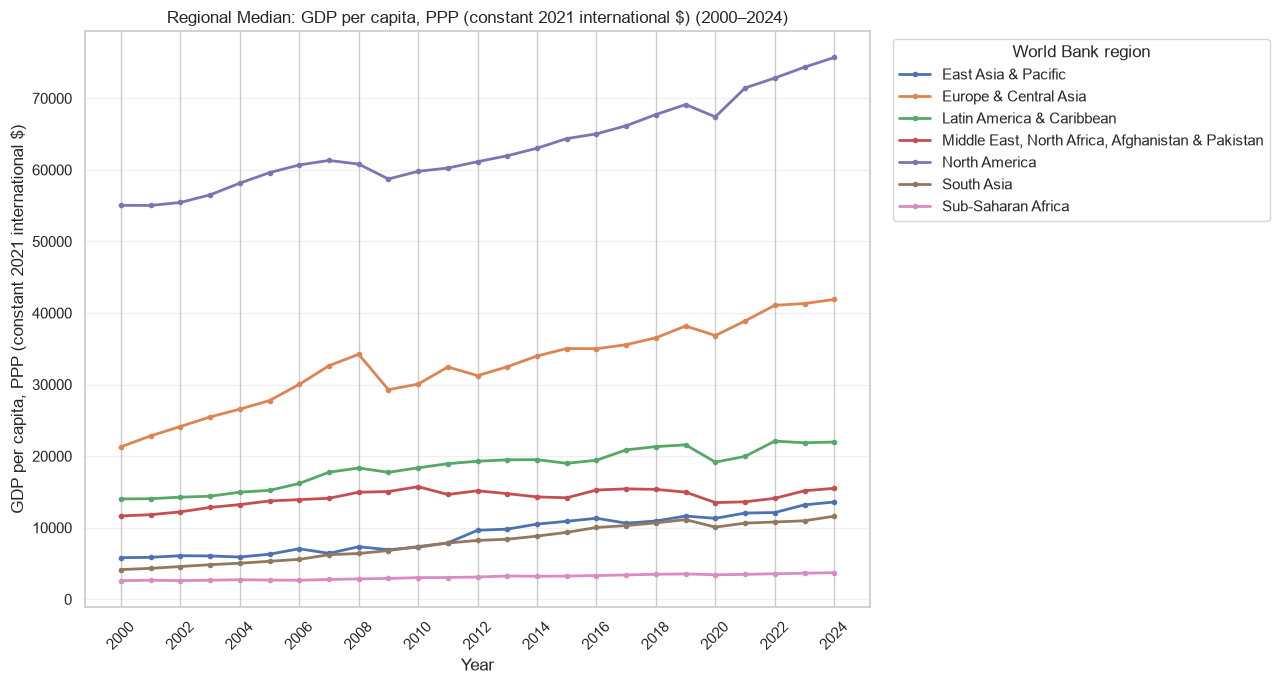

Regional summary and coverage: GDP per capita, PPP (constant 2021 international $)


,year,region,median,q25,q75,entities_with_values
0,2000,East Asia & Pacific,5809.01,3778.24,22468.53,31
7,2001,East Asia & Pacific,5860.83,3760.80,22813.55,31
14,2002,East Asia & Pacific,6085.89,3556.37,24052.07,31
21,2003,East Asia & Pacific,6054.66,3536.95,24735.73,31
28,2004,East Asia & Pacific,5901.21,3517.87,25874.02,31
...,...,...,...,...,...,...
146,2020,Sub-Saharan Africa,3424.36,2513.91,6397.14,46
153,2021,Sub-Saharan Africa,3478.69,2527.79,6521.43,46
160,2022,Sub-Saharan Africa,3566.05,2583.36,6614.41,46
167,2023,Sub-Saharan Africa,3647.14,2512.77,6736.63,46


In [24]:
# Work on a copy; preserve df_wb unchanged
regional_pc = df_wb.copy()

# Metrics to compare
REGIONAL_PC_METRICS = {
    "Nominal GDP per capita (current US$)": "gdp_per_capita_current_usd",
    "GDP per capita, PPP (constant 2021 international $)": (
        "gdp_per_capita_ppp_constant_2021"
    ),
}

# Remove World Bank aggregates where the flag is available
if "is_aggregate" in regional_pc.columns:
    aggregate_flag = (
        regional_pc["is_aggregate"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes", "y"])
    )
    regional_pc = regional_pc.loc[~aggregate_flag].copy()

# Standardise year and region columns
regional_pc["year"] = pd.to_numeric(
    regional_pc["year"], errors="coerce"
)

regional_pc["region"] = (
    regional_pc["region"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Restrict to our current EDA period
regional_pc = regional_pc.loc[
    regional_pc["year"].between(2000, 2024)
].copy()

# Calculate regional medians, quartiles and coverage
regional_pc_summaries = {}

for label, metric in REGIONAL_PC_METRICS.items():

    if metric not in regional_pc.columns:
        print(f"Column not found; skipping: {metric}")
        continue

    regional_pc[metric] = pd.to_numeric(
        regional_pc[metric], errors="coerce"
    )

    temp = regional_pc.dropna(
        subset=["year", "region", metric]
    )

    summary = (
        temp.groupby(["year", "region"])[metric]
        .agg(
            median="median",
            q25=lambda x: x.quantile(0.25),
            q75=lambda x: x.quantile(0.75),
            entities_with_values="count",
        )
        .reset_index()
        .sort_values(["region", "year"])
    )

    regional_pc_summaries[metric] = summary

    # Plot one line per region
    fig, ax = plt.subplots(figsize=(13, 7))

    for region, group in summary.groupby("region"):
        group = group.sort_values("year")

        ax.plot(
            group["year"],
            group["median"],
            marker="o",
            markersize=3,
            linewidth=2,
            label=region,
        )

    ax.set_title(f"Regional Median: {label} (2000–2024)")
    ax.set_xlabel("Year")
    ax.set_ylabel(label)
    ax.set_xticks(range(2000, 2025, 2))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(
        title="World Bank region",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )

    plt.tight_layout()
    plt.show()

    print(f"Regional summary and coverage: {label}")
    display(summary.round(2))

In [25]:
# Rebuild a diagnostic copy from the original dataset
metric = "gdp_per_capita_ppp_constant_2021"

diag = df_wb.copy()

entity_col = "country_iso3" if "country_iso3" in diag.columns else "country_name"
name_col = "country_name" if "country_name" in diag.columns else entity_col

diag["year"] = pd.to_numeric(diag["year"], errors="coerce")
diag[metric] = pd.to_numeric(diag[metric], errors="coerce")

# Exclude flagged aggregates, where the metadata is available
if "is_aggregate" in diag.columns:
    is_agg = (
        diag["is_aggregate"].astype(str).str.strip().str.lower()
        .isin(["true", "1", "yes", "y"])
    )
    diag = diag.loc[~is_agg].copy()

diag = diag.loc[
    diag["year"].between(2000, 2024)
    & diag["region"].notna()
].copy()

# 1. Check whether any country-year records are duplicated
duplicates = diag.duplicated(
    subset=[entity_col, "year"], keep=False
)

print("Duplicate country-year rows:", int(duplicates.sum()))

# 2. Regional coverage and distribution in 2024
regional_check = (
    diag.loc[diag["year"].eq(2024)]
    .groupby("region")
    .agg(
        countries=(entity_col, "nunique"),
        observations=(metric, "count"),
        median=(metric, "median"),
        q25=(metric, lambda x: x.quantile(0.25)),
        q75=(metric, lambda x: x.quantile(0.75)),
    )
    .sort_values("median", ascending=False)
)

display(regional_check.round(2))

# 3. Which entities contribute to the North America median?
print("North America — 2024")
display(
    diag.loc[
        diag["year"].eq(2024) & diag["region"].eq("North America"),
        [name_col, entity_col, metric]
    ].drop_duplicates().sort_values(metric)
)

# 4. Inspect the Europe & Central Asia dip around 2008–2009
print("Europe & Central Asia — 2008 and 2009")
display(
    diag.loc[
        diag["region"].eq("Europe & Central Asia")
        & diag["year"].isin([2008, 2009]),
        [name_col, entity_col, "year", metric]
    ]
    .sort_values(["year", metric])
    .round(2)
)

Duplicate country-year rows: 0


,countries,observations,median,q25,q75
region,,,,,
North America,3,3,75698.18,66616.13,89999.06
Europe & Central Asia,58,51,41891.17,25551.96,59229.86
Latin America & Caribbean,42,37,21970.35,15708.83,31960.16
"Middle East, North Africa, Afghanistan & Pakistan",23,21,15501.92,10468.27,47388.72
East Asia & Pacific,37,31,13592.46,6301.88,40798.04
South Asia,6,6,11604.56,8719.10,15151.18
Sub-Saharan Africa,48,46,3710.67,2585.78,6991.36


North America — 2024


,country_name,country_iso3,gdp_per_capita_ppp_constant_2021
6422,Canada,CAN,57534.091519
6637,United States,USA,75698.177335
6408,Bermuda,BMU,104299.944359


Europe & Central Asia — 2008 and 2009


,country_name,country_iso3,year,gdp_per_capita_ppp_constant_2021
2365,Tajikistan,TJK,2008,2308.09
2257,Kyrgyz Republic,KGZ,2008,4894.94
2384,Uzbekistan,UZB,2008,5145.99
2255,Kosovo,XKX,2008,7098.40
2374,Turkmenistan,TKM,2008,7870.03
...,...,...,...,...
2438,Channel Islands,CHI,2009,NaN
2484,Gibraltar,GIB,2009,NaN
2510,Isle of Man,IMN,2009,NaN
2535,Liechtenstein,LIE,2009,NaN


In [ ]:
# Official ISO3 codes for the 193 UN member states
UN_MEMBER_ISO3 = set("""
AFG ALB DZA AND AGO ATG ARG ARM AUS AUT AZE
BHS BHR BGD BRB BLR BEL BLZ BEN BTN BOL BIH BWA BRA BRN BGR BFA BDI
CPV KHM CMR CAN CAF TCD CHL CHN COL COM COG CRI CIV HRV CUB CYP CZE
PRK COD DNK DJI DMA DOM ECU EGY SLV GNQ ERI EST SWZ ETH
FJI FIN FRA GAB GMB GEO DEU GHA GRC GRD GTM GIN GNB GUY HTI HND HUN
ISL IND IDN IRN IRQ IRL ISR ITA JAM JPN JOR KAZ KEN KIR KWT KGZ
LAO LVA LBN LSO LBR LBY LIE LTU LUX MDG MWI MYS MDV MLI MLT MHL
MRT MUS MEX FSM MCO MNG MNE MAR MOZ MMR NAM NRU NPL NLD NZL NIC
NER NGA MKD NOR OMN PAK PLW PAN PNG PRY PER PHL POL PRT QAT KOR
MDA ROU RUS RWA KNA LCA VCT WSM SMR STP SAU SEN SRB SYC SLE SGP
SVK SVN SLB SOM ZAF SSD ESP LKA SDN SUR SWE CHE SYR TJK THA TLS
TGO TON TTO TUN TUR TKM TUV UGA UKR ARE GBR TZA USA URY UZB
VUT VEN VNM YEM ZMB ZWE HKG
""".split())


# Work on a copy; never modify the source DataFrame
wb_classified = df_wb.copy()

wb_classified["country_iso3_clean"] = (
    wb_classified["country_iso3"]
    .astype("string")
    .str.strip()
    .str.upper()
)

wb_classified["year"] = pd.to_numeric(
    wb_classified["year"], errors="coerce"
)

# Detect aggregates using the World Bank metadata
aggregate_flag = pd.Series(
    False, index=wb_classified.index
)

if "is_aggregate" in wb_classified.columns:
    aggregate_flag |= (
        wb_classified["is_aggregate"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes", "y"])
    )

if "region" in wb_classified.columns:
    aggregate_flag |= (
        wb_classified["region"]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("aggregates")
        .fillna(False)
    )

if "income_group" in wb_classified.columns:
    aggregate_flag |= (
        wb_classified["income_group"]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("aggregates")
        .fillna(False)
    )

missing_iso3 = (
    wb_classified["country_iso3_clean"].isna()
    | wb_classified["country_iso3_clean"].eq("")
)

is_un_member = wb_classified[
    "country_iso3_clean"
].isin(UN_MEMBER_ISO3)

wb_classified["entity_type"] = np.select(
    [
        aggregate_flag,
        missing_iso3,
        is_un_member,
    ],
    [
        "World Bank aggregate",
        "Missing ISO3 - review",
        "UN member state",
    ],
    default="Other non-aggregate WB entity"
)

# A sorted entity crosswalk: one row per ISO3 code
entity_cols = [
    "country_name",
    "country_iso2",
    "country_iso3_clean",
    "entity_type",
    "region",
    "income_group",
]

entity_cols = [
    col for col in entity_cols
    if col in wb_classified.columns
]

entity_crosswalk = (
    wb_classified[entity_cols]
    .drop_duplicates(subset=["country_iso3_clean"])
    .sort_values(["entity_type", "country_iso3_clean"])
    .reset_index(drop=True)
)

print("Entity counts:")
display(
    entity_crosswalk.groupby("entity_type")
    .agg(unique_entities=("country_iso3_clean", "nunique"))
)

print("All entities, sorted by classification and ISO3:")
display(entity_crosswalk)

# Check that all UN member codes are represented
found_un_codes = set(
    entity_crosswalk.loc[
        entity_crosswalk["entity_type"].eq("UN member state"),
        "country_iso3_clean"
    ].dropna()
)

print("UN member codes present:", len(found_un_codes), "/ 193")
print("UN member codes not found:", sorted(UN_MEMBER_ISO3 - found_un_codes))

# Inspect the non-UN entity group
print("Other non-aggregate entities:")
display(
    entity_crosswalk.loc[
        entity_crosswalk["entity_type"].eq(
            "Other non-aggregate WB entity"
        )
    ].sort_values("country_iso3_clean")
)

Entity counts:


,unique_entities
entity_type,
Other non-aggregate WB entity,23
UN member state,194
World Bank aggregate,49


All entities, sorted by classification and ISO3:


,country_name,country_iso2,country_iso3_clean,entity_type,region,income_group
0,Aruba,AW,ABW,Other non-aggregate WB entity,Latin America & Caribbean,High income
1,American Samoa,AS,ASM,Other non-aggregate WB entity,East Asia & Pacific,High income
2,Bermuda,BM,BMU,Other non-aggregate WB entity,North America,High income
3,Channel Islands,JG,CHI,Other non-aggregate WB entity,Europe & Central Asia,High income
4,Curacao,CW,CUW,Other non-aggregate WB entity,Latin America & Caribbean,High income
...,...,...,...,...,...,...
261,"Middle East, North Africa, Afghanistan & Pakis...",T3,TMN,World Bank aggregate,Aggregates,Aggregates
262,South Asia (IDA & IBRD),T5,TSA,World Bank aggregate,Aggregates,Aggregates
263,Sub-Saharan Africa (IDA & IBRD countries),T6,TSS,World Bank aggregate,Aggregates,Aggregates
264,Upper middle income,XT,UMC,World Bank aggregate,Aggregates,Aggregates


UN member codes present: 194 / 193
UN member codes not found: []
Other non-aggregate entities:


,country_name,country_iso2,country_iso3_clean,entity_type,region,income_group
0,Aruba,AW,ABW,Other non-aggregate WB entity,Latin America & Caribbean,High income
1,American Samoa,AS,ASM,Other non-aggregate WB entity,East Asia & Pacific,High income
2,Bermuda,BM,BMU,Other non-aggregate WB entity,North America,High income
3,Channel Islands,JG,CHI,Other non-aggregate WB entity,Europe & Central Asia,High income
4,Curacao,CW,CUW,Other non-aggregate WB entity,Latin America & Caribbean,High income
5,Cayman Islands,KY,CYM,Other non-aggregate WB entity,Latin America & Caribbean,High income
6,Faroe Islands,FO,FRO,Other non-aggregate WB entity,Europe & Central Asia,High income
7,Gibraltar,GI,GIB,Other non-aggregate WB entity,Europe & Central Asia,High income
8,Greenland,GL,GRL,Other non-aggregate WB entity,Europe & Central Asia,High income
9,Guam,GU,GUM,Other non-aggregate WB entity,East Asia & Pacific,High income


In [27]:
CORE_INDICATORS = [
    # Nominal and real GDP measures
    "gdp_current_usd",
    "gdp_per_capita_current_usd",
    "gdp_constant_2015_usd",
    "gdp_per_capita_constant_2015_usd",
    "gdp_ppp_constant_2021",
    "gdp_per_capita_ppp_constant_2021",

    # Growth and inflation
    "real_gdp_growth_pct",
    "real_gdp_per_capita_growth_pct",
    "inflation_cpi_pct",
    "inflation_gdp_deflator_pct",

    # Population and settlement
    "population_total",
    "population_density_per_sq_km",
    "population_growth_pct",
    "urban_population_pct",
    "rural_population_pct",

    # Other core development measures
    "electricity_access_pct",
    "unemployment_pct",
    "life_expectancy_years",
]

# Derive rural population percentage if it is not already present
if (
    "rural_population_pct" not in wb_classified.columns
    and {"rural_population", "population_total"}.issubset(
        wb_classified.columns
    )
):
    population = pd.to_numeric(
        wb_classified["population_total"], errors="coerce"
    )
    rural = pd.to_numeric(
        wb_classified["rural_population"], errors="coerce"
    )

    valid = population.gt(0) & rural.notna()

    wb_classified["rural_population_pct"] = np.nan
    wb_classified.loc[valid, "rural_population_pct"] = (
        rural.loc[valid] / population.loc[valid] * 100
    )

indicator_cols = [
    col for col in CORE_INDICATORS
    if col in wb_classified.columns
]

print("Indicators included:")
print(indicator_cols)

print("\nIndicators not found in the combined dataset:")
print(sorted(set(CORE_INDICATORS) - set(indicator_cols)))

# Ensure indicator values are numeric in the analysis copy
for col in indicator_cols:
    wb_classified[col] = pd.to_numeric(
        wb_classified[col], errors="coerce"
    )

wb_classified[indicator_cols] = (
    wb_classified[indicator_cols]
    .replace([np.inf, -np.inf], np.nan)
)

Indicators included:
['gdp_current_usd', 'gdp_per_capita_current_usd', 'gdp_constant_2015_usd', 'gdp_per_capita_constant_2015_usd', 'gdp_ppp_constant_2021', 'gdp_per_capita_ppp_constant_2021', 'real_gdp_growth_pct', 'real_gdp_per_capita_growth_pct', 'inflation_cpi_pct', 'inflation_gdp_deflator_pct', 'population_total', 'population_density_per_sq_km', 'population_growth_pct', 'urban_population_pct', 'rural_population_pct', 'electricity_access_pct', 'unemployment_pct', 'life_expectancy_years']

Indicators not found in the combined dataset:
[]


Rows in duplicate entity-year keys: 0


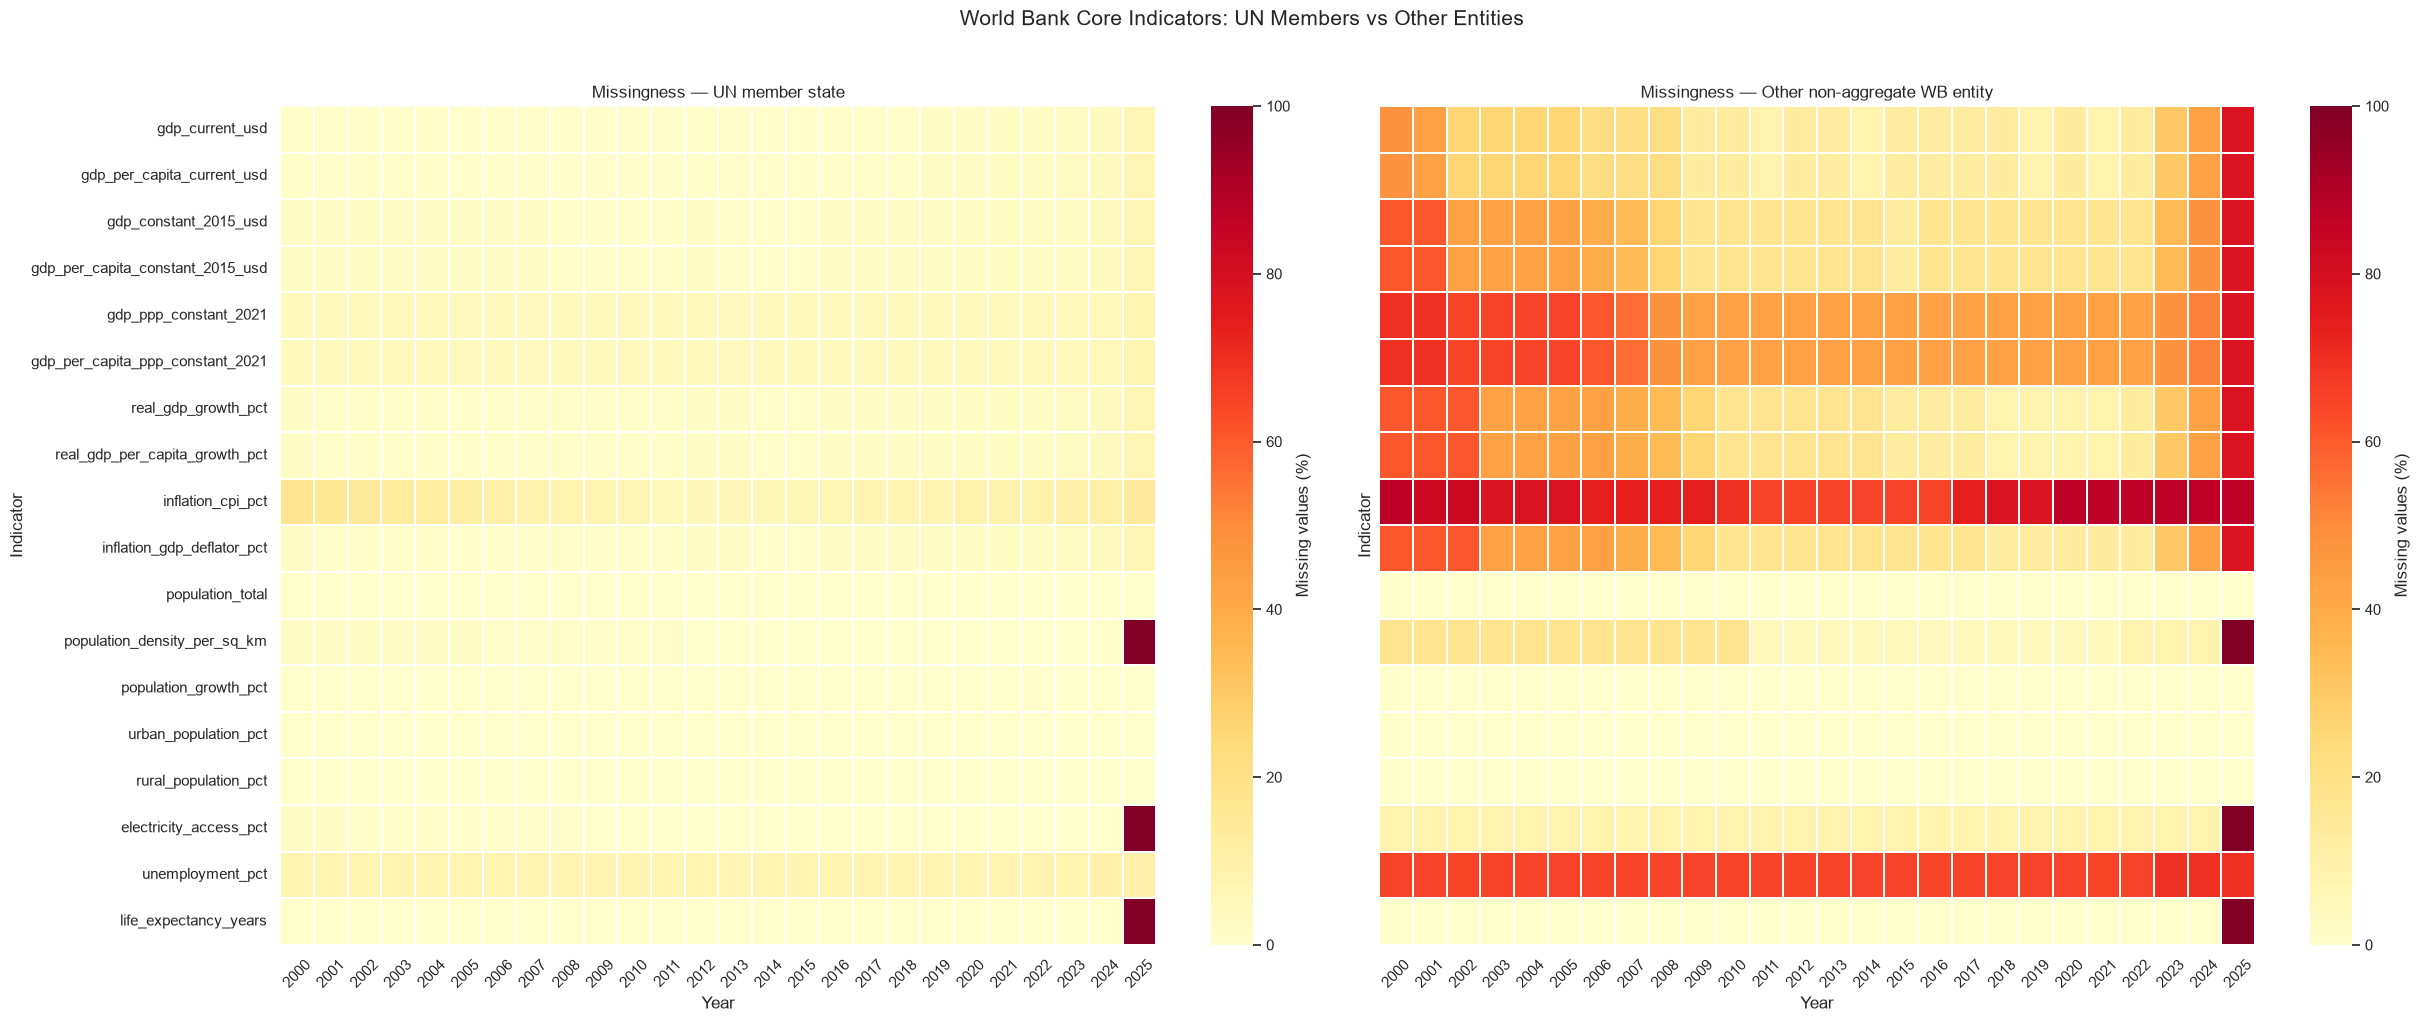

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

comparison_groups = [
    "UN member state",
    "Other non-aggregate WB entity",
]

analysis_df = wb_classified.loc[
    wb_classified["entity_type"].isin(comparison_groups)
].copy()

# Verify there is at most one record per entity-year
duplicate_mask = analysis_df.duplicated(
    subset=["country_iso3_clean", "year"],
    keep=False
)

print(
    "Rows in duplicate entity-year keys:",
    int(duplicate_mask.sum())
)

if duplicate_mask.any():
    display(
        analysis_df.loc[
            duplicate_mask,
            ["country_name", "country_iso3_clean", "year"]
        ].sort_values(["country_iso3_clean", "year"]).head(20)
    )
    raise ValueError(
        "Resolve duplicate entity-year records before computing heatmaps."
    )

years = sorted(analysis_df["year"].dropna().unique())

fig, axes = plt.subplots(
    1, 2, figsize=(25, 10), sharey=True
)

for ax, group_name in zip(axes, comparison_groups):
    subset = analysis_df.loc[
        analysis_df["entity_type"].eq(group_name)
    ]

    # Percentage missing for each indicator in each year
    yearly_missingness = (
        subset.groupby("year")[indicator_cols]
        .agg(lambda values: values.isna().mean() * 100)
        .reindex(years)
    )

    sns.heatmap(
        yearly_missingness.T,
        ax=ax,
        cmap="YlOrRd",
        vmin=0,
        vmax=100,
        linewidths=0.25,
        cbar_kws={"label": "Missing values (%)"},
    )

    ax.set_title(f"Missingness — {group_name}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Indicator")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle(
    "World Bank Core Indicators: UN Members vs Other Entities",
    fontsize=15,
    y=1.02
)
plt.tight_layout()
plt.show()

In [29]:
annual_entity_counts = (
    analysis_df.groupby(["year", "entity_type"])[
        "country_iso3_clean"
    ]
    .nunique()
    .unstack("entity_type")
    .reindex(years)
)

print("Distinct entities represented in each year:")
display(annual_entity_counts)

# Save the classification and diagnostic outputs
WB_DIAGNOSTICS_DIR = REPORT_DIR / "worldbank_cleaning_diagnostics"
WB_DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

entity_crosswalk.to_csv(
    WB_DIAGNOSTICS_DIR / "worldbank_entity_classification.csv",
    index=False
)

annual_entity_counts.to_csv(
    WB_DIAGNOSTICS_DIR / "worldbank_entity_coverage_by_year.csv"
)

print("Classification and coverage tables saved to:")
print(WB_DIAGNOSTICS_DIR)

Distinct entities represented in each year:


entity_type,Other non-aggregate WB entity,UN member state
year,,
2000,23,194
2001,23,194
2002,23,194
2003,23,194
2004,23,194
2005,23,194
2006,23,194
2007,23,194
2008,23,194


Classification and coverage tables saved to:
d:\DA2402\Project\EarthQuake\reports\worldbank_cleaning_diagnostics


# Data Cleaning

In [30]:
# Select only the 193 UN member states
df_un_core = wb_classified.loc[
    wb_classified["entity_type"].eq("UN member state")
].copy()

# Restrict to the intended analysis period
df_un_core["year"] = pd.to_numeric(
    df_un_core["year"], errors="coerce"
)

df_un_core = df_un_core.loc[
    df_un_core["year"].between(2000, 2025)
].copy()

# Standardise ISO codes
if "country_iso3_clean" in df_un_core.columns:
    df_un_core["country_iso3"] = (
        df_un_core["country_iso3_clean"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

if "country_iso2" in df_un_core.columns:
    df_un_core["country_iso2"] = (
        df_un_core["country_iso2"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

# Retain useful country identifiers and metadata
metadata_cols = [
    "country_name",
    "country_iso2",
    "country_iso3",
    "year",
    "region",
    "income_group",
]

metadata_cols = [
    col for col in metadata_cols
    if col in df_un_core.columns
]

# Keep only core indicators that actually exist
core_cols = [
    col for col in CORE_INDICATORS
    if col in df_un_core.columns
]

# Preserve one consistent country-year key
selected_cols = list(dict.fromkeys(metadata_cols + core_cols))

df_un_core = df_un_core[selected_cols].copy()

# Ensure indicator fields are numeric
for col in core_cols:
    df_un_core[col] = pd.to_numeric(
        df_un_core[col], errors="coerce"
    )

# Check country-year uniqueness before saving
duplicate_rows = df_un_core.duplicated(
    subset=["country_iso3", "year"],
    keep=False
)

print("Dataset shape:", df_un_core.shape)
print(
    "Unique UN member states:",
    df_un_core["country_iso3"].nunique()
)
print(
    "Distinct years:",
    sorted(df_un_core["year"].dropna().unique())
)
print(
    "Rows involved in duplicate country-year keys:",
    int(duplicate_rows.sum())
)

if duplicate_rows.any():
    display(
        df_un_core.loc[duplicate_rows]
        .sort_values(["country_iso3", "year"])
        .head(20)
    )
    raise ValueError(
        "Resolve duplicate country-year records before exporting."
    )

display(df_un_core)

Dataset shape: (5044, 24)
Unique UN member states: 194
Distinct years: [np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Rows involved in duplicate country-year keys: 0


,country_name,country_iso2,country_iso3,year,region,income_group,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years
0,Afghanistan,AF,AFG,2000,"Middle East, North Africa, Afghanistan & Pakistan",Low income,3.521418e+09,174.930991,6.206548e+09,308.318270,3.256738e+10,1617.826475,NaN,NaN,NaN,NaN,20130327.0,30.863847,1.212176,18.558200,81.441802,4.4,7.897,55.005
3,Albania,AL,ALB,2000,Europe & Central Asia,Upper middle income,3.584570e+09,1160.420471,6.153077e+09,1991.914359,2.033194e+10,6581.989092,7.462859,8.149968,0.050018,5.919573,3089027.0,112.738212,-0.637357,41.613583,58.386411,99.4,19.023,74.826
4,Algeria,DZ,DZA,2000,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,5.479040e+10,1772.928691,1.098116e+11,3553.324205,3.571940e+11,11558.220469,3.800000,2.357264,0.339163,22.678009,30903893.0,12.975343,1.399669,59.852124,40.147877,98.6,29.770,70.576
6,Andorra,AD,AND,2000,Europe & Central Asia,High income,1.432606e+09,21810.248743,2.240766e+09,34113.817378,3.600139e+09,54809.144168,3.528362,3.567766,NaN,28.741553,65685.0,139.755319,-0.038053,92.255936,7.744538,100.0,NaN,81.863
7,Angola,AO,AGO,2000,Sub-Saharan Africa,Lower middle income,9.129595e+09,563.733796,3.518276e+10,2172.463267,1.100365e+11,6794.530211,3.054624,-0.302928,324.996872,418.018992,16194869.0,12.990189,3.312287,50.507065,49.492935,24.2,16.646,46.501
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6908,"Venezuela, RB",VE,VEN,2025,Latin America & Caribbean,Lower middle income,9.966124e+10,3494.813887,4.331281e+10,1518.847427,NaN,NaN,1.570681,1.174067,NaN,227.093065,28516896.0,NaN,0.391245,89.321911,10.678087,NaN,5.307,NaN
6909,Viet Nam,VN,VNM,2025,East Asia & Pacific,Upper middle income,5.146972e+11,5065.990919,4.377073e+11,4308.205075,1.570444e+12,15457.349940,8.018830,7.369388,3.309993,3.331761,101598527.0,NaN,0.603045,38.829916,61.170084,NaN,1.523,NaN
6913,"Yemen, Rep.",YE,YEM,2025,"Middle East, North Africa, Afghanistan & Pakistan",Low income,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41773878.0,NaN,2.891792,37.033666,62.966333,NaN,17.322,NaN
6914,Zambia,ZM,ZMB,2025,Sub-Saharan Africa,Lower middle income,2.887981e+10,1317.877716,2.971029e+10,1355.775363,8.200734e+10,3742.256463,3.757728,0.921974,13.909910,5.628684,21913874.0,NaN,2.771097,45.917151,54.082847,NaN,5.918,NaN


In [31]:
WB_DIAGNOSTICS_DIR

WindowsPath('d:/DA2402/Project/EarthQuake/reports/worldbank_cleaning_diagnostics')

In [32]:
core_missingness = pd.DataFrame({
    "missing_count": df_un_core[core_cols].isna().sum(),
    "missing_percent": df_un_core[core_cols].isna().mean() * 100,
    "available_count": df_un_core[core_cols].notna().sum(),
})

core_missingness = core_missingness.sort_values(
    "missing_percent",
    ascending=False
)

display(core_missingness.round(2))

try:

    core_missingness.to_csv(str(WB_DIAGNOSTICS_DIR/"un_core_missingness.csv"),index=False)

except PermissionError:
    print("Try Closing the csv file if opened")

,missing_count,missing_percent,available_count
inflation_cpi_pct,486,9.64,4558
unemployment_pct,401,7.95,4643
population_density_per_sq_km,231,4.58,4813
gdp_per_capita_ppp_constant_2021,230,4.56,4814
gdp_ppp_constant_2021,230,4.56,4814
electricity_access_pct,219,4.34,4825
life_expectancy_years,194,3.85,4850
gdp_per_capita_constant_2015_usd,114,2.26,4930
gdp_constant_2015_usd,114,2.26,4930
inflation_gdp_deflator_pct,108,2.14,4936


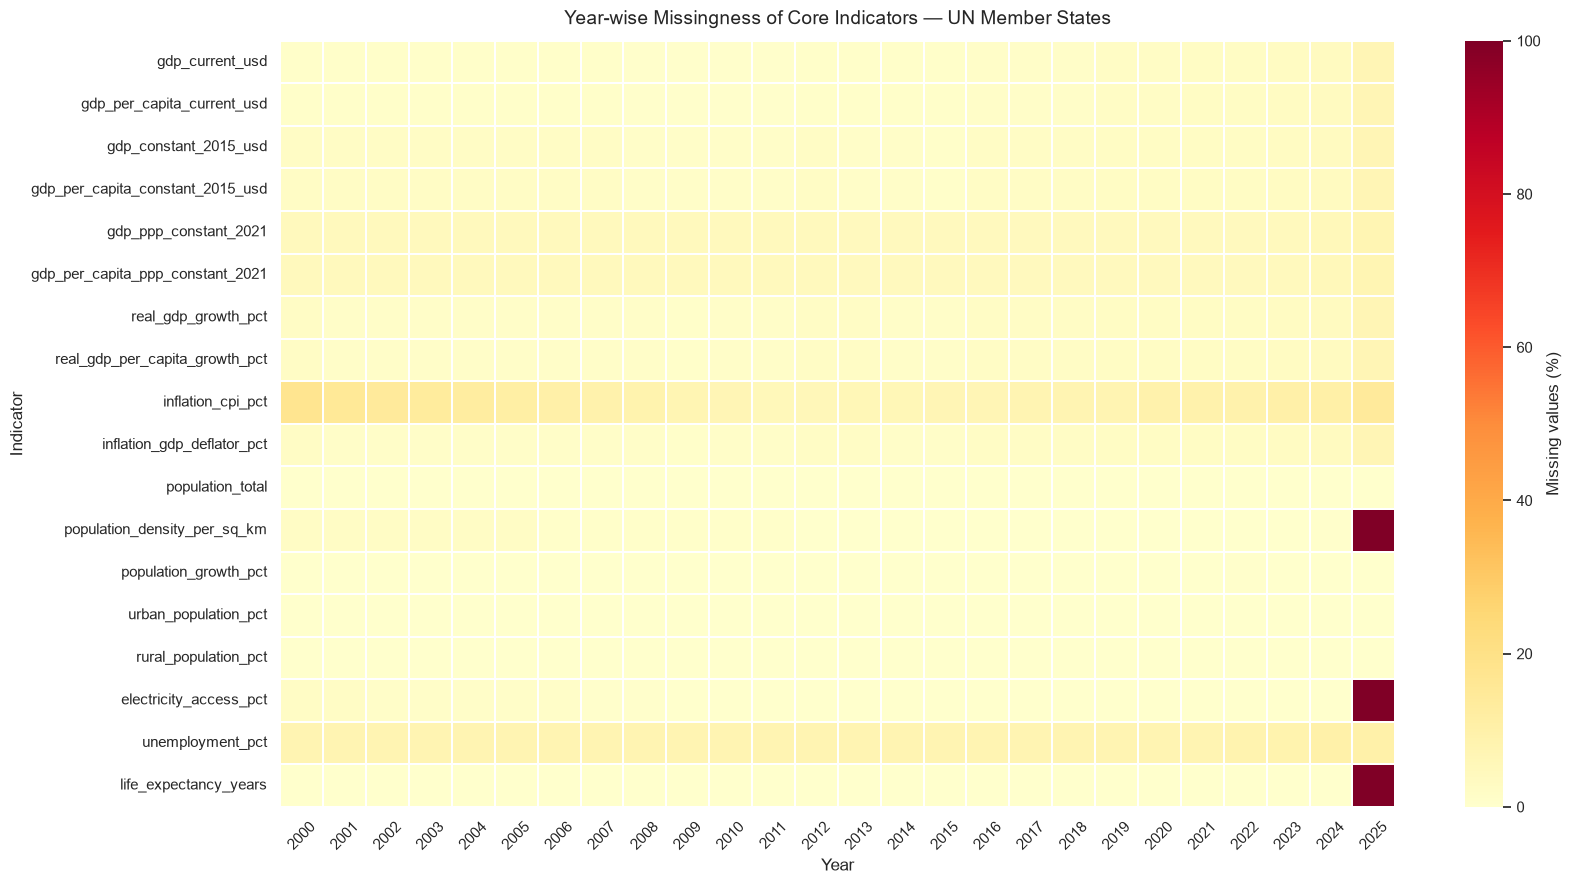

In [33]:
un_missing_by_year = (
    df_un_core.groupby("year")[core_cols]
    .agg(lambda values: values.isna().mean() * 100)
    .reindex(range(2000, 2026))
)

plt.figure(figsize=(17, 9))

sns.heatmap(
    un_missing_by_year.T,
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.25,
    cbar_kws={"label": "Missing values (%)"},
)

plt.title(
    "Year-wise Missingness of Core Indicators — UN Member States",
    fontsize=14,
    pad=12,
)
plt.xlabel("Year")
plt.ylabel("Indicator")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Work only with UN member-state observations
un_data = wb_classified.loc[
    wb_classified["entity_type"].eq("UN member state")
].copy()

un_data["year"] = pd.to_numeric(un_data["year"], errors="coerce")

un_data["country_iso3_clean"] = (
    un_data["country_iso3_clean"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Keep the chosen time period
un_data = un_data.loc[
    un_data["year"].between(2000, 2025)
].copy()

# Convert selected indicator columns to numeric
for col in indicator_cols:
    un_data[col] = pd.to_numeric(
        un_data[col], errors="coerce"
    )

un_data[indicator_cols] = un_data[indicator_cols].replace(
    [np.inf, -np.inf], np.nan
)

# Verify uniqueness before creating the complete panel
duplicate_mask = un_data.duplicated(
    subset=["country_iso3_clean", "year"],
    keep=False
)

if duplicate_mask.any():
    display(
        un_data.loc[
            duplicate_mask,
            ["country_name", "country_iso3_clean", "year"]
        ].sort_values(["country_iso3_clean", "year"]).head(20)
    )
    raise ValueError(
        "Duplicate country-year records found. Resolve them before continuing."
    )

# Country-level metadata
metadata_cols = [
    col for col in [
        "country_name",
        "country_iso2",
        "region",
        "income_group",
    ]
    if col in un_data.columns
]

country_metadata = (
    un_data.sort_values("year")
    .drop_duplicates("country_iso3_clean")
    [["country_iso3_clean"] + metadata_cols]
)

# Start with all 193 UN member ISO3 codes, even if any are absent
# from the World Bank observations
country_universe = pd.DataFrame({
    "country_iso3_clean": sorted(UN_MEMBER_ISO3)
})

country_metadata = country_universe.merge(
    country_metadata,
    on="country_iso3_clean",
    how="left",
    validate="one_to_one"
)

country_metadata["country_iso3"] = (
    country_metadata["country_iso3_clean"]
)

# Build every country × year combination from 2000 through 2025
years_df = pd.DataFrame({
    "year": range(2000, 2026)
})

complete_panel = country_metadata.merge(
    years_df,
    how="cross"
)

# Merge observed indicator values into the complete panel
value_cols = [
    "country_iso3_clean",
    "year",
] + indicator_cols

observed_values = un_data[value_cols].copy()

complete_panel = complete_panel.merge(
    observed_values,
    on=["country_iso3_clean", "year"],
    how="left",
    validate="one_to_one"
)

print("Complete panel shape:", complete_panel.shape)
print("Countries:", complete_panel["country_iso3_clean"].nunique())
print("Years:", complete_panel["year"].nunique())

In [35]:
# Cell 34: Create country-wise missingness pivot tables

# Keep only indicator columns that exist in the completed panel
indicator_cols = [
    col for col in indicator_cols
    if col in complete_panel.columns
]

# 1. Percentage of years missing for each indicator and country
country_missing_pct = (
    complete_panel
    .groupby("country_iso3_clean")[indicator_cols]
    .agg(lambda s: s.isna().mean() * 100)
)

# 2. Number of missing years for each indicator and country
country_missing_count = (
    complete_panel
    .groupby("country_iso3_clean")[indicator_cols]
    .agg(lambda s: s.isna().sum())
    .astype(int)
)

# 3. Keep country identifiers and metadata
report_metadata_cols = [
    col for col in [
        "country_name",
        "country_iso2",
        "country_iso3",
        "region",
    ]
    if col in complete_panel.columns
]

country_metadata_report = (
    complete_panel[
        ["country_iso3_clean"] + report_metadata_cols
    ]
    .drop_duplicates(subset=["country_iso3_clean"])
    .set_index("country_iso3_clean")
)

# 4. Construct the percentage report
country_missingness_pct_report = (
    country_metadata_report
    .join(country_missing_pct.add_suffix("_missing_pct"))
)

pct_cols = [
    col for col in country_missingness_pct_report.columns
    if col.endswith("_missing_pct")
]

country_missingness_pct_report["average_core_missing_pct"] = (
    country_missingness_pct_report[pct_cols].mean(axis=1)
)

country_missingness_pct_report = (
    country_missingness_pct_report
    .sort_values("average_core_missing_pct", ascending=False)
)

# 5. Construct the missing-year count report
country_missingness_count_report = (
    country_metadata_report
    .join(country_missing_count.add_suffix("_missing_years"))
)

count_cols = [
    col for col in country_missingness_count_report.columns
    if col.endswith("_missing_years")
]

country_missingness_count_report["total_missing_core_cells"] = (
    country_missingness_count_report[count_cols].sum(axis=1)
)

# Use the same country ordering in both reports
country_missingness_count_report = (
    country_missingness_count_report
    .reindex(country_missingness_pct_report.index)
)

# 6. Inspect the results
print("Countries with highest average missingness:")
display(country_missingness_pct_report.head(20).round(2))

print("\nCorresponding missing-year counts:")
display(country_missingness_count_report.head(20))

print("\nReport dimensions:")
print("Percentage report:", country_missingness_pct_report.shape)
print("Count report:", country_missingness_count_report.shape)

Countries with highest average missingness:


,country_name,country_iso2,country_iso3,region,gdp_current_usd_missing_pct,gdp_per_capita_current_usd_missing_pct,gdp_constant_2015_usd_missing_pct,gdp_per_capita_constant_2015_usd_missing_pct,gdp_ppp_constant_2021_missing_pct,gdp_per_capita_ppp_constant_2021_missing_pct,real_gdp_growth_pct_missing_pct,real_gdp_per_capita_growth_pct_missing_pct,inflation_cpi_pct_missing_pct,inflation_gdp_deflator_pct_missing_pct,population_total_missing_pct,population_density_per_sq_km_missing_pct,population_growth_pct_missing_pct,urban_population_pct_missing_pct,rural_population_pct_missing_pct,electricity_access_pct_missing_pct,unemployment_pct_missing_pct,life_expectancy_years_missing_pct,average_core_missing_pct
country_iso3_clean,,,,,,,,,,,,,,,,,,,,,,,
PRK,"Korea, Dem. People's Rep.",KP,PRK,East Asia & Pacific,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,0.0,3.85,0.00,0.0,0.0,38.46,0.00,3.85,58.12
SSD,South Sudan,SS,SSD,Sub-Saharan Africa,69.23,69.23,69.23,69.23,100.00,100.00,73.08,73.08,38.46,73.08,0.0,50.00,0.00,0.0,0.0,30.77,7.69,3.85,45.94
LIE,Liechtenstein,LI,LIE,Europe & Central Asia,3.85,3.85,96.15,96.15,100.00,100.00,61.54,61.54,100.00,61.54,0.0,3.85,0.00,0.0,0.0,3.85,100.00,3.85,44.23
ERI,Eritrea,ER,ERI,Sub-Saharan Africa,53.85,53.85,53.85,53.85,100.00,100.00,53.85,53.85,100.00,53.85,0.0,3.85,0.00,0.0,0.0,3.85,0.00,3.85,38.25
YEM,"Yemen, Rep.",YE,YEM,"Middle East, North Africa, Afghanistan & Pakistan",26.92,26.92,26.92,26.92,100.00,100.00,26.92,26.92,42.31,26.92,0.0,3.85,0.00,0.0,0.0,3.85,0.00,3.85,24.57
MCO,Monaco,MC,MCO,Europe & Central Asia,3.85,3.85,3.85,3.85,100.00,100.00,3.85,3.85,100.00,3.85,0.0,3.85,0.00,0.0,0.0,3.85,100.00,3.85,24.36
DJI,Djibouti,DJ,DJI,"Middle East, North Africa, Afghanistan & Pakistan",0.00,0.00,50.00,50.00,50.00,50.00,53.85,53.85,3.85,53.85,0.0,3.85,0.00,0.0,0.0,3.85,0.00,3.85,20.94
CUB,Cuba,CU,CUB,Latin America & Caribbean,19.23,19.23,3.85,3.85,100.00,100.00,3.85,3.85,100.00,3.85,0.0,3.85,0.00,0.0,0.0,3.85,0.00,3.85,20.51
VEN,"Venezuela, RB",VE,VEN,Latin America & Caribbean,0.00,0.00,0.00,0.00,100.00,100.00,0.00,0.00,69.23,0.00,0.0,3.85,0.00,0.0,0.0,3.85,0.00,3.85,15.60



Corresponding missing-year counts:


,country_name,country_iso2,country_iso3,region,gdp_current_usd_missing_years,gdp_per_capita_current_usd_missing_years,gdp_constant_2015_usd_missing_years,gdp_per_capita_constant_2015_usd_missing_years,gdp_ppp_constant_2021_missing_years,gdp_per_capita_ppp_constant_2021_missing_years,real_gdp_growth_pct_missing_years,real_gdp_per_capita_growth_pct_missing_years,inflation_cpi_pct_missing_years,inflation_gdp_deflator_pct_missing_years,population_total_missing_years,population_density_per_sq_km_missing_years,population_growth_pct_missing_years,urban_population_pct_missing_years,rural_population_pct_missing_years,electricity_access_pct_missing_years,unemployment_pct_missing_years,life_expectancy_years_missing_years,total_missing_core_cells
country_iso3_clean,,,,,,,,,,,,,,,,,,,,,,,
PRK,"Korea, Dem. People's Rep.",KP,PRK,East Asia & Pacific,26,26,26,26,26,26,26,26,26,26,0,1,0,0,0,10,0,1,272
SSD,South Sudan,SS,SSD,Sub-Saharan Africa,18,18,18,18,26,26,19,19,10,19,0,13,0,0,0,8,2,1,215
LIE,Liechtenstein,LI,LIE,Europe & Central Asia,1,1,25,25,26,26,16,16,26,16,0,1,0,0,0,1,26,1,207
ERI,Eritrea,ER,ERI,Sub-Saharan Africa,14,14,14,14,26,26,14,14,26,14,0,1,0,0,0,1,0,1,179
YEM,"Yemen, Rep.",YE,YEM,"Middle East, North Africa, Afghanistan & Pakistan",7,7,7,7,26,26,7,7,11,7,0,1,0,0,0,1,0,1,115
MCO,Monaco,MC,MCO,Europe & Central Asia,1,1,1,1,26,26,1,1,26,1,0,1,0,0,0,1,26,1,114
DJI,Djibouti,DJ,DJI,"Middle East, North Africa, Afghanistan & Pakistan",0,0,13,13,13,13,14,14,1,14,0,1,0,0,0,1,0,1,98
CUB,Cuba,CU,CUB,Latin America & Caribbean,5,5,1,1,26,26,1,1,26,1,0,1,0,0,0,1,0,1,96
VEN,"Venezuela, RB",VE,VEN,Latin America & Caribbean,0,0,0,0,26,26,0,0,18,0,0,1,0,0,0,1,0,1,73



Report dimensions:
Percentage report: (194, 23)
Count report: (194, 23)


In [36]:
try:
    country_missingness_count_report.to_csv(WB_DIAGNOSTICS_DIR/"country_missingness_count.csv",index=False)
    country_missingness_pct_report.to_csv(WB_DIAGNOSTICS_DIR/"country_missingness_pct.csv",index=False)

except PermissionError:
    print("Try closing the csv files")

In [37]:
# Focus on the two most recent years
RECENT_YEARS = [2024, 2025]

recent_panel = complete_panel.loc[
    complete_panel["year"].isin(RECENT_YEARS)
].copy()

# Keep only core indicators that exist in the panel
recent_indicators = [
    col for col in indicator_cols
    if col in recent_panel.columns
]

# Summarise missing and available values by year and indicator
records = []

for year in RECENT_YEARS:
    year_data = recent_panel.loc[
        recent_panel["year"].eq(year)
    ]

    for col in recent_indicators:
        missing_count = int(year_data[col].isna().sum())
        total_count = len(year_data)

        records.append({
            "year": year,
            "indicator": col,
            "total_countries": total_count,
            "missing_count": missing_count,
            "available_count": total_count - missing_count,
            "missing_percent": (
                missing_count / total_count * 100
                if total_count else np.nan
            ),
        })

recent_missingness = pd.DataFrame(records)

# Display the detailed summary
display(
    recent_missingness.sort_values(
        ["indicator", "year"]
    ).round(2)
)

# Pivot: indicators as rows, years as columns
recent_missing_pct_pivot = recent_missingness.pivot(
    index="indicator",
    columns="year",
    values="missing_percent"
).reindex(columns=RECENT_YEARS)

print("Percentage of countries with missing values:")
display(recent_missing_pct_pivot.round(2))

,year,indicator,total_countries,missing_count,available_count,missing_percent
15,2024,electricity_access_pct,194,0,194,0.00
33,2025,electricity_access_pct,194,194,0,100.00
2,2024,gdp_constant_2015_usd,194,7,187,3.61
20,2025,gdp_constant_2015_usd,194,13,181,6.70
0,2024,gdp_current_usd,194,7,187,3.61
18,2025,gdp_current_usd,194,13,181,6.70
3,2024,gdp_per_capita_constant_2015_usd,194,7,187,3.61
21,2025,gdp_per_capita_constant_2015_usd,194,13,181,6.70
1,2024,gdp_per_capita_current_usd,194,7,187,3.61
19,2025,gdp_per_capita_current_usd,194,13,181,6.70


Percentage of countries with missing values:


year,2024,2025
indicator,,
electricity_access_pct,0.00,100.00
gdp_constant_2015_usd,3.61,6.70
gdp_current_usd,3.61,6.70
gdp_per_capita_constant_2015_usd,3.61,6.70
gdp_per_capita_current_usd,3.61,6.70
gdp_per_capita_ppp_constant_2021,5.15,7.22
gdp_ppp_constant_2021,5.15,7.22
inflation_cpi_pct,10.82,14.43
inflation_gdp_deflator_pct,3.61,6.70


In [38]:
recent_missing_pct_pivot.to_csv(WB_DIAGNOSTICS_DIR/"recent_year_missingness_pct.csv",index=False)
recent_missingness.to_csv(WB_DIAGNOSTICS_DIR/"recent_year_missingness_ct.csv",index=False)

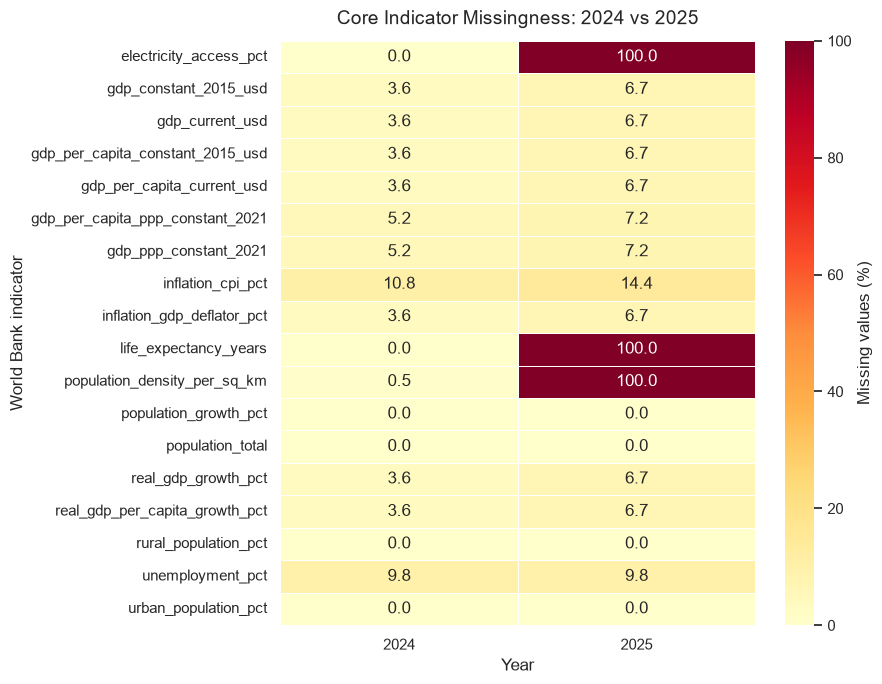

In [39]:
plt.figure(figsize=(9, max(7, len(recent_indicators) * 0.38)))

sns.heatmap(
    recent_missing_pct_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.4,
    cbar_kws={"label": "Missing values (%)"}
)

plt.title(
    "Core Indicator Missingness: 2024 vs 2025",
    fontsize=14,
    pad=12
)
plt.xlabel("Year")
plt.ylabel("World Bank indicator")
plt.tight_layout()
plt.show()

In [40]:
country_name_col = (
    "country_name"
    if "country_name" in recent_panel.columns
    else "country_iso3_clean"
)

for year in RECENT_YEARS:
    year_data = recent_panel.loc[
        recent_panel["year"].eq(year)
    ].copy()

    country_report = year_data[
        [
            "country_iso3_clean",
            country_name_col
        ] + recent_indicators
    ].copy()

    # Count missing core indicators for each country
    country_report["missing_indicator_count"] = (
        country_report[recent_indicators].isna().sum(axis=1)
    )

    country_report["missing_indicator_pct"] = (
        country_report[recent_indicators]
        .isna()
        .mean(axis=1)
        .mul(100)
    )

    # Show the countries with the most missing indicators
    country_report = country_report.sort_values(
        ["missing_indicator_count", country_name_col],
        ascending=[False, True]
    )

    print(f"\nCountries with the most missing core indicators in {year}:")
    display(country_report.head(25).round(2))


Countries with the most missing core indicators in 2024:


,country_iso3_clean,country_name,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years,missing_indicator_count,missing_indicator_pct
1376,ERI,Eritrea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3535603.0,29.27,1.86,34.54,65.46,55.3,5.95,68.89,10,55.56
3716,PRK,"Korea, Dem. People's Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26498823.0,220.07,0.30,63.86,36.14,61.4,3.54,73.74,10,55.56
4080,SMR,San Marino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.24,NaN,33977.0,555.18,0.34,97.16,2.84,100.0,NaN,85.82,10,55.56
4158,SSD,South Sudan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,91.44,NaN,11943408.0,18.90,3.93,21.38,78.62,5.4,NaN,57.74,10,55.56
4366,SYR,Syrian Arab Republic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24672760.0,134.36,4.47,72.08,27.92,89.3,13.36,72.56,10,55.56
4964,YEM,"Yemen, Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40583164.0,76.87,2.98,36.81,63.19,86.3,16.97,69.44,10,55.56
2650,LIE,Liechtenstein,8.905764e+09,220167.23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40450.0,252.81,1.50,14.66,85.34,100.0,NaN,84.20,9,50.00
1090,CUB,Cuba,NaN,NaN,8.104615e+10,7381.40,NaN,NaN,-1.06,-0.70,NaN,32.22,10979783.0,105.78,-0.36,77.17,22.83,100.0,1.76,78.26,5,27.78
2832,MCO,Monaco,1.112579e+10,288001.57,9.548428e+09,247170.10,NaN,NaN,8.51,9.42,NaN,2.39,38631.0,18536.95,-0.84,100.00,0.00,100.0,NaN,86.50,4,22.22
4860,VEN,"Venezuela, RB",1.205661e+11,4244.46,4.264303e+10,1501.22,NaN,NaN,5.52,5.14,NaN,55.45,28405543.0,32.20,0.37,89.29,10.71,100.0,5.32,72.67,3,16.67



Countries with the most missing core indicators in 2025:


,country_iso3_clean,country_name,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years,missing_indicator_count,missing_indicator_pct
2651,LIE,Liechtenstein,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41024.0,NaN,1.41,14.63,85.37,NaN,NaN,NaN,14,77.78
2833,MCO,Monaco,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38341.0,NaN,-0.75,100.00,0.00,NaN,NaN,NaN,14,77.78
4159,SSD,South Sudan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12188788.0,NaN,2.03,21.68,78.32,NaN,NaN,NaN,14,77.78
25,AFG,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43844111.0,NaN,2.77,25.94,74.06,NaN,13.35,NaN,13,72.22
1091,CUB,Cuba,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10937203.0,NaN,-0.39,77.23,22.77,NaN,1.75,NaN,13,72.22
1377,ERI,Eritrea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3607003.0,NaN,2.00,34.54,65.46,NaN,5.98,NaN,13,72.22
3717,PRK,"Korea, Dem. People's Rep.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26571036.0,NaN,0.27,64.19,35.81,NaN,3.54,NaN,13,72.22
2547,LBN,Lebanon,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.60,NaN,5849421.0,NaN,0.75,90.96,9.04,NaN,NaN,NaN,13,72.22
4081,SMR,San Marino,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.30,NaN,34109.0,NaN,0.39,97.19,2.81,NaN,NaN,NaN,13,72.22
4367,SYR,Syrian Arab Republic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25620427.0,NaN,3.77,72.08,27.92,NaN,13.57,NaN,13,72.22


In [ ]:
# Recalculate from the latest complete panel, not the older CSV report
country_count = complete_panel["country_iso3_clean"].nunique()

print("Number of distinct country codes:", country_count)``



# Indicator-wise percentage missing for each country
country_missing_pct = (
    complete_panel
    .groupby("country_iso3_clean")[core_cols]
    .agg(lambda s: s.isna().mean() * 100)
)

# Country metadata
metadata_cols = [
    col for col in [
        "country_name",
        "country_iso2",
        "country_iso3",
        "region",
        "income_group",
    ]
    if col in complete_panel.columns
]

country_metadata = (
    complete_panel
    .sort_values("year")
    .drop_duplicates("country_iso3_clean")
    .set_index("country_iso3_clean")[metadata_cols]
)

country_audit = country_metadata.join(
    country_missing_pct.add_suffix("_missing_pct")
)

pct_cols = [
    col for col in country_audit.columns
    if col.endswith("_missing_pct")
]

# Country-level screening metrics
country_audit["average_core_missing_pct"] = (
    country_audit[pct_cols].mean(axis=1)
)

country_audit["indicators_over_50pct_missing"] = (
    country_audit[pct_cols].gt(50).sum(axis=1)
)

country_audit["indicators_100pct_missing"] = (
    country_audit[pct_cols].ge(99.99).sum(axis=1)
)

# Compare alternative thresholds before deciding
threshold_sensitivity = pd.DataFrame({
    "threshold_pct": [1,2,3,4,5,10,15,20, 25, 30, 35, 40, 50],
})

threshold_sensitivity["countries_flagged"] = (
    threshold_sensitivity["threshold_pct"].apply(
        lambda t: int(
            country_audit["average_core_missing_pct"].gt(t).sum()
        )
    )
)

print("How sensitive is the exclusion decision to our threshold?")
display(threshold_sensitivity)

# List countries above 35%
MISSINGNESS_THRESHOLD = 35.0

flagged_countries = (
    country_audit.loc[
        country_audit["average_core_missing_pct"]
        > MISSINGNESS_THRESHOLD
    ]
    .reset_index()
    .sort_values("average_core_missing_pct", ascending=False)
)

flagged_summary_cols = [
    "country_iso3_clean",
    "country_name",
    "average_core_missing_pct",
    "indicators_over_50pct_missing",
    "indicators_100pct_missing",
]

print("\nCountries flagged above 35%:")
display(flagged_countries[flagged_summary_cols].round(2))

print("\nIndicator-level missingness for flagged countries:")
display(
    flagged_countries[
        ["country_iso3_clean", "country_name"] + pct_cols
    ].round(1)
)

Number of distinct country codes: 194
How sensitive is the exclusion decision to our threshold?


,threshold_pct,countries_flagged
0,1,49
1,2,37
2,3,32
3,4,30
4,5,25
5,10,14
6,15,9
7,20,8
8,25,4
9,30,4



Countries flagged above 35%:


,country_iso3_clean,country_name,average_core_missing_pct,indicators_over_50pct_missing,indicators_100pct_missing
2,PRK,"Korea, Dem. People's Rep.",58.12,10,10
3,SSD,South Sudan,45.94,9,2
0,LIE,Liechtenstein,44.23,9,4
1,ERI,Eritrea,38.25,10,3



Indicator-level missingness for flagged countries:


,country_iso3_clean,country_name,gdp_current_usd_missing_pct,gdp_per_capita_current_usd_missing_pct,gdp_constant_2015_usd_missing_pct,gdp_per_capita_constant_2015_usd_missing_pct,gdp_ppp_constant_2021_missing_pct,gdp_per_capita_ppp_constant_2021_missing_pct,real_gdp_growth_pct_missing_pct,real_gdp_per_capita_growth_pct_missing_pct,inflation_cpi_pct_missing_pct,inflation_gdp_deflator_pct_missing_pct,population_total_missing_pct,population_density_per_sq_km_missing_pct,population_growth_pct_missing_pct,urban_population_pct_missing_pct,rural_population_pct_missing_pct,electricity_access_pct_missing_pct,unemployment_pct_missing_pct,life_expectancy_years_missing_pct
2,PRK,"Korea, Dem. People's Rep.",100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,0.0,3.8,0.0,0.0,0.0,38.5,0.0,3.8
3,SSD,South Sudan,69.2,69.2,69.2,69.2,100.0,100.0,73.1,73.1,38.5,73.1,0.0,50.0,0.0,0.0,0.0,30.8,7.7,3.8
0,LIE,Liechtenstein,3.8,3.8,96.2,96.2,100.0,100.0,61.5,61.5,100.0,61.5,0.0,3.8,0.0,0.0,0.0,3.8,100.0,3.8
1,ERI,Eritrea,53.8,53.8,53.8,53.8,100.0,100.0,53.8,53.8,100.0,53.8,0.0,3.8,0.0,0.0,0.0,3.8,0.0,3.8


In [42]:
df_un_core.dtypes

country_name                            str
country_iso2                         string
country_iso3                         string
year                                  int64
region                                  str
income_group                            str
gdp_current_usd                     float64
gdp_per_capita_current_usd          float64
gdp_constant_2015_usd               float64
gdp_per_capita_constant_2015_usd    float64
gdp_ppp_constant_2021               float64
gdp_per_capita_ppp_constant_2021    float64
real_gdp_growth_pct                 float64
real_gdp_per_capita_growth_pct      float64
inflation_cpi_pct                   float64
inflation_gdp_deflator_pct          float64
population_total                    float64
population_density_per_sq_km        float64
population_growth_pct               float64
urban_population_pct                float64
rural_population_pct                float64
electricity_access_pct              float64
unemployment_pct                

In [43]:
# Provisional country exclusion threshold
MISSINGNESS_THRESHOLD = 25.0

# Identify indicator-specific missingness columns
pct_cols = [
    col for col in country_audit.columns
    if col.endswith("_missing_pct")
]

# Recalculate the average to ensure it exists
country_audit["average_core_missing_pct"] = (
    country_audit[pct_cols].mean(axis=1)
)

# Create a review table for countries exceeding the threshold
excluded_country_report = (
    country_audit.loc[
        country_audit["average_core_missing_pct"]
        > MISSINGNESS_THRESHOLD
    ]
    .reset_index()
    .sort_values("average_core_missing_pct", ascending=False)
)

review_cols = [
    col for col in [
        "country_iso3_clean",
        "country_name",
        "average_core_missing_pct",
        "indicators_over_50pct_missing",
        "indicators_100pct_missing",
    ]
    if col in excluded_country_report.columns
]

print("Countries flagged above 25% average missingness:")
display(excluded_country_report[review_cols].round(2))

excluded_codes = set(
    excluded_country_report["country_iso3_clean"].astype(str)
)

print(f"\nCountries flagged: {len(excluded_codes)}")
print("ISO3 codes:", sorted(excluded_codes))

Countries flagged above 25% average missingness:


,country_iso3_clean,country_name,average_core_missing_pct,indicators_over_50pct_missing,indicators_100pct_missing
2,PRK,"Korea, Dem. People's Rep.",58.12,10,10
3,SSD,South Sudan,45.94,9,2
0,LIE,Liechtenstein,44.23,9,4
1,ERI,Eritrea,38.25,10,3



Countries flagged: 4
ISO3 codes: ['ERI', 'LIE', 'PRK', 'SSD']


In [44]:
# Preserve the original complete panel
df_un_core_all = complete_panel.copy()

# Create the candidate analysis dataset
df_un_core_candidate = complete_panel.loc[
    ~complete_panel["country_iso3_clean"].isin(excluded_codes)
].copy()

print("Before filtering:")
print("Countries:", df_un_core_all["country_iso3_clean"].nunique())
print("Rows:", len(df_un_core_all))

print("\nAfter filtering:")
print("Countries:", df_un_core_candidate["country_iso3_clean"].nunique())
print("Rows:", len(df_un_core_candidate))

# Verify country-year uniqueness
assert not df_un_core_candidate.duplicated(
    ["country_iso3_clean", "year"]
).any(), "Duplicate country-year rows detected."

Before filtering:
Countries: 194
Rows: 5044

After filtering:
Countries: 190
Rows: 4940


,missing_count,missing_percent,available_count
inflation_cpi_pct,398,8.06,4542
unemployment_pct,373,7.55,4567
population_density_per_sq_km,215,4.35,4725
electricity_access_pct,199,4.03,4741
life_expectancy_years,190,3.85,4750
gdp_per_capita_ppp_constant_2021,126,2.55,4814
gdp_ppp_constant_2021,126,2.55,4814
real_gdp_per_capita_growth_pct,33,0.67,4907
inflation_gdp_deflator_pct,33,0.67,4907
real_gdp_growth_pct,33,0.67,4907


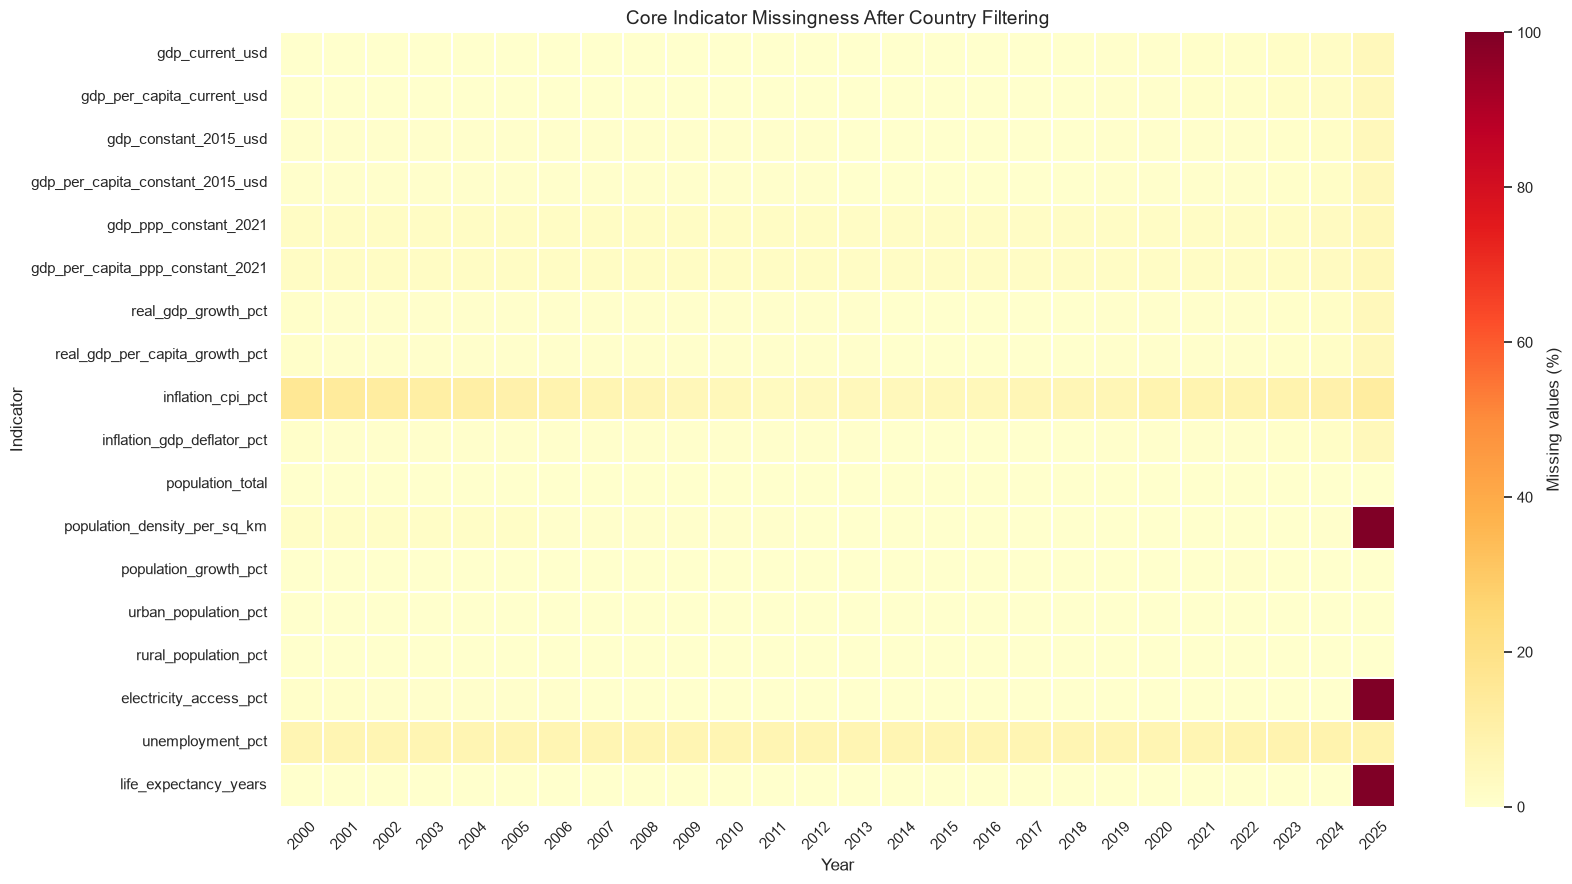

In [45]:
core_cols = [
    col for col in CORE_INDICATORS
    if col in df_un_core_candidate.columns
]

post_filter_missingness = pd.DataFrame({
    "missing_count": df_un_core_candidate[core_cols].isna().sum(),
    "missing_percent": (
        df_un_core_candidate[core_cols].isna().mean() * 100
    ),
    "available_count": df_un_core_candidate[core_cols].notna().sum(),
}).sort_values("missing_percent", ascending=False)

display(post_filter_missingness.round(2))

# Year-wise missingness after country filtering
post_filter_missing_by_year = (
    df_un_core_candidate
    .groupby("year")[core_cols]
    .agg(lambda s: s.isna().mean() * 100)
    .reindex(range(2000, 2026))
)

plt.figure(figsize=(17, 9))

sns.heatmap(
    post_filter_missing_by_year.T,
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.25,
    cbar_kws={"label": "Missing values (%)"},
)

plt.title(
    "Core Indicator Missingness After Country Filtering",
    fontsize=14,
)
plt.xlabel("Year")
plt.ylabel("Indicator")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [46]:
gap_records = []

for iso3, group in df_un_core_candidate.groupby("country_iso3_clean"):
    group = group.sort_values("year").reset_index(drop=True)
    years = group["year"].to_numpy()

    for col in core_cols:
        values = group[col]
        missing = values.isna().to_numpy()
        observed_positions = np.flatnonzero(~missing)

        total_missing = int(missing.sum())
        all_missing = len(values) > 0 and total_missing == len(values)

        if all_missing:
            first_observed_year = np.nan
            last_observed_year = np.nan
            leading_missing = len(values)
            trailing_missing = len(values)
            internal_missing = 0
            internal_gap_episodes = 0
            longest_internal_gap = 0

        else:
            first_pos = int(observed_positions[0])
            last_pos = int(observed_positions[-1])

            first_observed_year = years[first_pos]
            last_observed_year = years[last_pos]

            leading_missing = first_pos
            trailing_missing = len(values) - 1 - last_pos

            # Missing values between the first and last observations
            internal_mask = missing[first_pos:last_pos + 1]
            internal_missing = int(internal_mask.sum())

            # Count consecutive runs inside the observed span
            starts = internal_mask & ~np.r_[False, internal_mask[:-1]]
            internal_gap_episodes = int(starts.sum())

            # Length of the longest internal missing run
            longest_internal_gap = 0
            current_run = 0

            for is_missing in internal_mask:
                if is_missing:
                    current_run += 1
                    longest_internal_gap = max(
                        longest_internal_gap, current_run
                    )
                else:
                    current_run = 0

        gap_records.append({
            "country_iso3": iso3,
            "indicator": col,
            "years_in_panel": len(values),
            "total_missing_years": total_missing,
            "missing_percent": (
                total_missing / len(values) * 100
                if len(values) else np.nan
            ),
            "first_observed_year": first_observed_year,
            "last_observed_year": last_observed_year,
            "leading_missing_years": leading_missing,
            "trailing_missing_years": trailing_missing,
            "internal_missing_years": internal_missing,
            "internal_gap_episodes": internal_gap_episodes,
            "longest_internal_gap_years": longest_internal_gap,
            "all_years_missing": all_missing,
        })

gap_audit = pd.DataFrame(gap_records)

print("Longest internal gaps:")
display(
    gap_audit.sort_values(
        ["longest_internal_gap_years", "missing_percent"],
        ascending=False,
    ).head(30)
)

print("\nIndicators with entirely missing country series:")
display(
    gap_audit.loc[gap_audit["all_years_missing"]]
    .sort_values(["indicator", "country_iso3"])
)

Longest internal gaps:


,country_iso3,indicator,years_in_panel,total_missing_years,missing_percent,first_observed_year,last_observed_year,leading_missing_years,trailing_missing_years,internal_missing_years,internal_gap_episodes,longest_internal_gap_years,all_years_missing
440,BRB,inflation_cpi_pct,26,3,11.538462,2000.0,2025.0,0,0,3,1,3,False
2834,SUR,inflation_cpi_pct,26,2,7.692308,2000.0,2025.0,0,0,2,1,2,False
2928,SYC,population_growth_pct,26,1,3.846154,2000.0,2025.0,0,0,1,1,1,False
62,AND,inflation_cpi_pct,26,26,100.000000,NaN,NaN,26,26,0,0,0,True
70,AND,unemployment_pct,26,26,100.000000,NaN,NaN,26,26,0,0,0,True
142,ATG,unemployment_pct,26,26,100.000000,NaN,NaN,26,26,0,0,0,True
742,CUB,gdp_ppp_constant_2021,26,26,100.000000,NaN,NaN,26,26,0,0,0,True
743,CUB,gdp_per_capita_ppp_constant_2021,26,26,100.000000,NaN,NaN,26,26,0,0,0,True
746,CUB,inflation_cpi_pct,26,26,100.000000,NaN,NaN,26,26,0,0,0,True
844,DMA,unemployment_pct,26,26,100.000000,NaN,NaN,26,26,0,0,0,True



Indicators with entirely missing country series:


,country_iso3,indicator,years_in_panel,total_missing_years,missing_percent,first_observed_year,last_observed_year,leading_missing_years,trailing_missing_years,internal_missing_years,internal_gap_episodes,longest_internal_gap_years,all_years_missing
743,CUB,gdp_per_capita_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
1913,MCO,gdp_per_capita_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
3281,VEN,gdp_per_capita_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
3353,YEM,gdp_per_capita_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
742,CUB,gdp_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
1912,MCO,gdp_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
3280,VEN,gdp_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
3352,YEM,gdp_ppp_constant_2021,26,26,100.0,NaN,NaN,26,26,0,0,0,True
62,AND,inflation_cpi_pct,26,26,100.0,NaN,NaN,26,26,0,0,0,True
746,CUB,inflation_cpi_pct,26,26,100.0,NaN,NaN,26,26,0,0,0,True


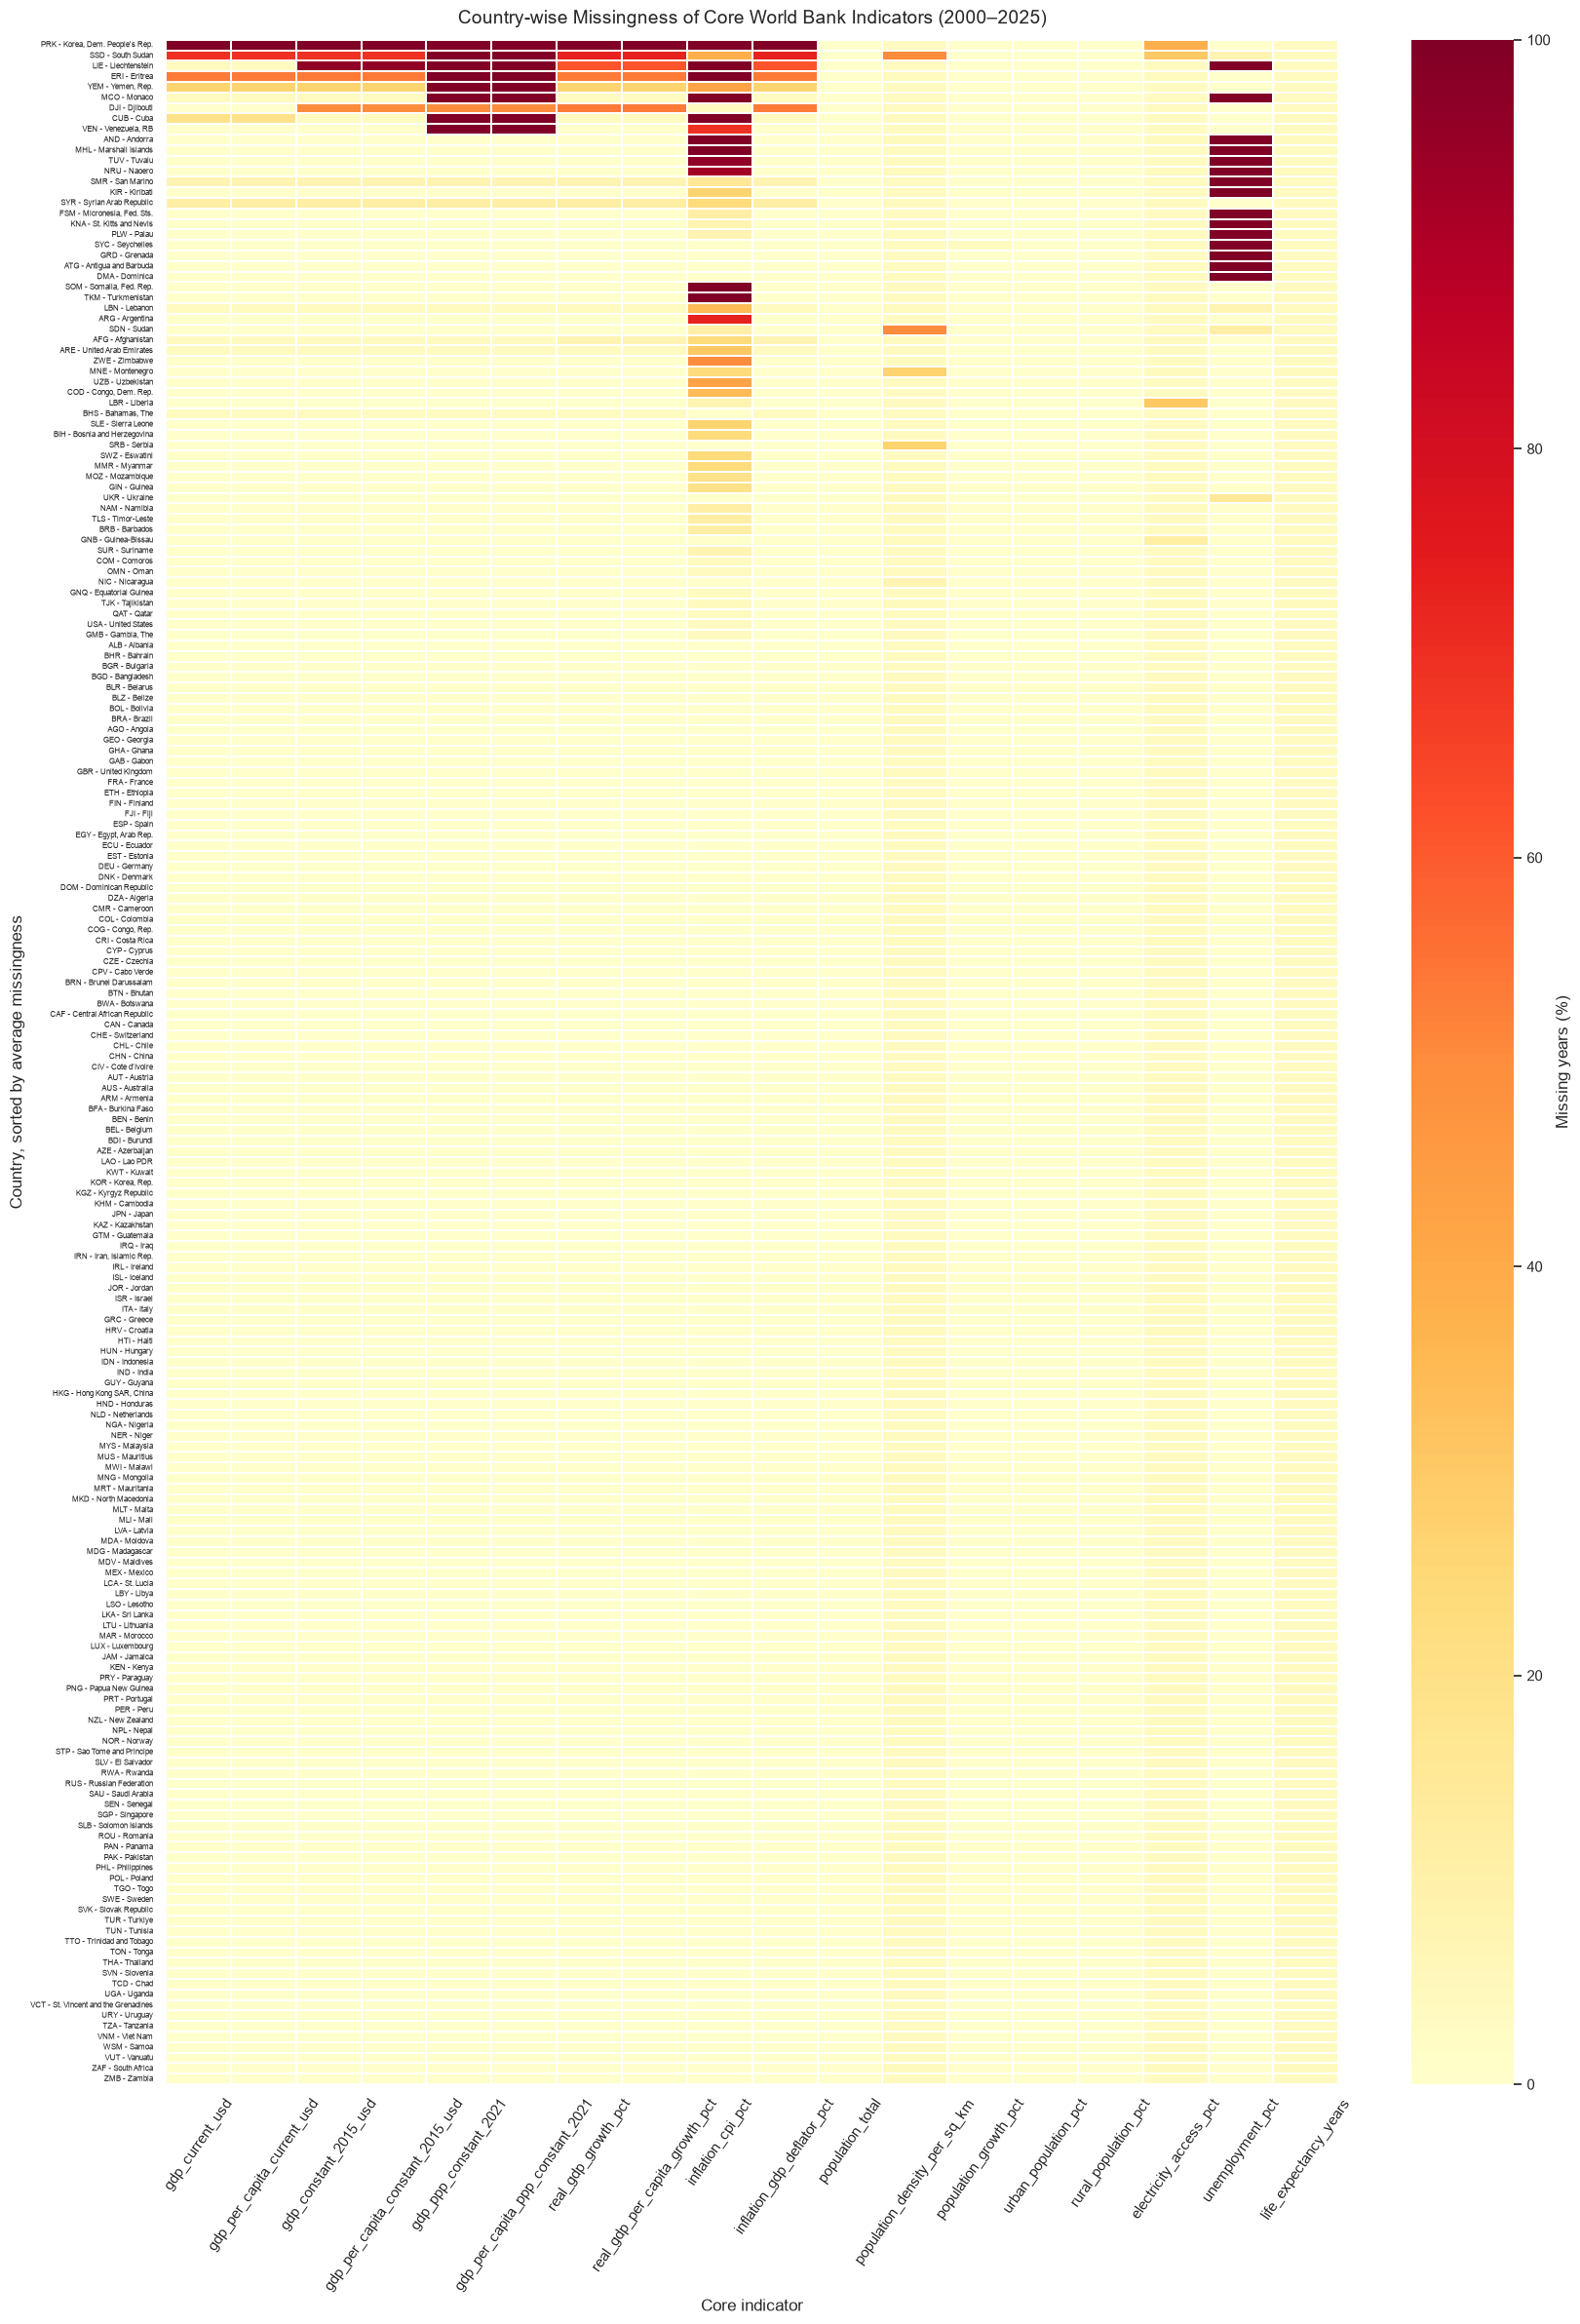

Countries displayed: 194


In [47]:
# Use the full UN-member panel BEFORE excluding high-missingness countries
missing_source = complete_panel.copy()

indicator_cols_plot = [
    col for col in CORE_INDICATORS
    if col in missing_source.columns
]

# Country-wise missing percentage for each indicator
country_indicator_missing_pct = (
    missing_source
    .groupby("country_iso3_clean")[indicator_cols_plot]
    .agg(lambda s: s.isna().mean() * 100)
)

# Sort countries by their average missingness across core indicators
country_indicator_missing_pct["average_missing_pct"] = (
    country_indicator_missing_pct.mean(axis=1)
)

country_indicator_missing_pct = (
    country_indicator_missing_pct
    .sort_values("average_missing_pct", ascending=False)
)

# Separate the plotting matrix from the average column
heatmap_data = country_indicator_missing_pct.drop(
    columns="average_missing_pct"
)

# Add country names to the ISO3 codes for easier interpretation
if "country_name" in missing_source.columns:
    country_names = (
        missing_source[
            ["country_iso3_clean", "country_name"]
        ]
        .drop_duplicates("country_iso3_clean")
        .set_index("country_iso3_clean")["country_name"]
    )

    country_labels = [
        f"{iso3} - {country_names.get(iso3, '')}"
        for iso3 in heatmap_data.index
    ]
else:
    country_labels = heatmap_data.index.tolist()

plt.figure(figsize=(17, 24))

ax = sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.15,
    cbar_kws={"label": "Missing years (%)"}
)

ax.set_title(
    "Country-wise Missingness of Core World Bank Indicators (2000–2025)",
    fontsize=14,
    pad=12
)
ax.set_xlabel("Core indicator")
ax.set_ylabel("Country, sorted by average missingness")

ax.set_yticks(np.arange(len(country_labels)) + 0.5)
ax.set_yticklabels(country_labels, fontsize=5.5, rotation=0)
ax.tick_params(axis="x", labelrotation=55)

plt.tight_layout()
plt.show()

print("Countries displayed:", len(heatmap_data))

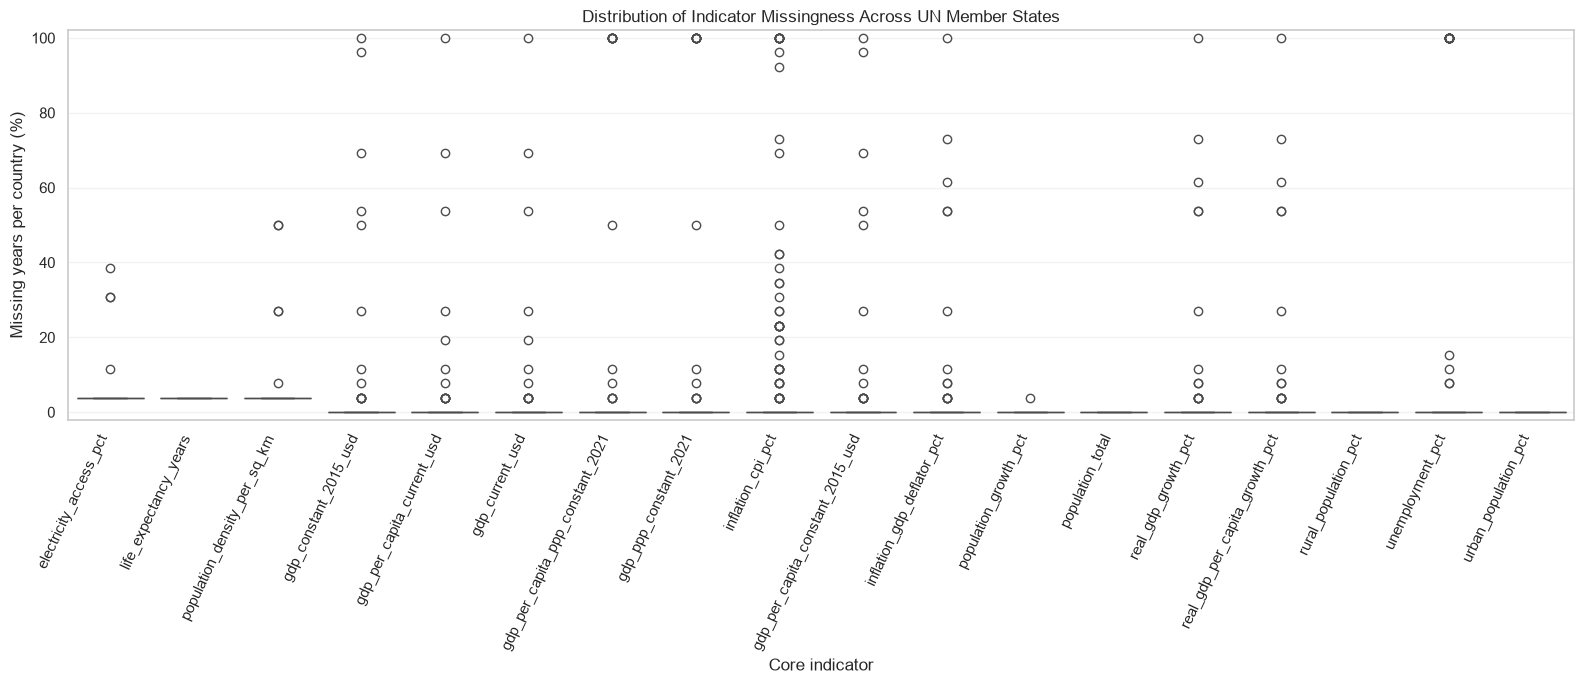

In [48]:
# Reshape country-level missingness into long format
missingness_long = (
    heatmap_data
    .reset_index()
    .melt(
        id_vars="country_iso3_clean",
        var_name="indicator",
        value_name="missing_pct"
    )
)

# Order indicators from highest to lowest median missingness
indicator_order = (
    missingness_long.groupby("indicator")["missing_pct"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)

plt.figure(figsize=(16, 7))

sns.boxplot(
    data=missingness_long,
    x="indicator",
    y="missing_pct",
    order=indicator_order,
    showfliers=True
)

plt.title(
    "Distribution of Indicator Missingness Across UN Member States"
)
plt.xlabel("Core indicator")
plt.ylabel("Missing years per country (%)")
plt.xticks(rotation=65, ha="right")
plt.ylim(-2, 102)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [49]:
missingness_country_summary = pd.DataFrame({
    "median_country_missing_pct": heatmap_data.median(axis=0),
    "mean_country_missing_pct": heatmap_data.mean(axis=0),
    "countries_with_any_missing": heatmap_data.gt(0).sum(axis=0),
    "countries_over_25pct_missing": heatmap_data.gt(25).sum(axis=0),
    "countries_over_50pct_missing": heatmap_data.gt(50).sum(axis=0),
    "countries_entire_series_missing": heatmap_data.ge(100).sum(axis=0),
})

missingness_country_summary = (
    missingness_country_summary
    .sort_values("median_country_missing_pct", ascending=False)
)

display(missingness_country_summary.round(2))

,median_country_missing_pct,mean_country_missing_pct,countries_with_any_missing,countries_over_25pct_missing,countries_over_50pct_missing,countries_entire_series_missing
life_expectancy_years,3.85,3.85,194,0,0,0
electricity_access_pct,3.85,4.34,194,3,0,0
population_density_per_sq_km,3.85,4.58,194,4,0,0
gdp_current_usd,0.00,1.61,13,4,3,1
gdp_per_capita_current_usd,0.00,1.61,13,4,3,1
gdp_constant_2015_usd,0.00,2.26,14,6,4,1
real_gdp_growth_pct,0.00,2.14,14,6,5,1
gdp_per_capita_constant_2015_usd,0.00,2.26,14,6,4,1
gdp_ppp_constant_2021,0.00,4.56,15,9,8,8
gdp_per_capita_ppp_constant_2021,0.00,4.56,15,9,8,8


In [50]:
# Cell 52: Audit recent-year missingness against historical coverage

panel = complete_panel.copy()

audit_cols = [
    col for col in CORE_INDICATORS
    if col in panel.columns
]

panel["year"] = pd.to_numeric(panel["year"], errors="coerce")

# Calculate percentage missing by year for each indicator
year_missing_pct = (
    panel.groupby("year")[audit_cols]
    .agg(lambda s: s.isna().mean() * 100)
    .sort_index()
)

# Confirm the years we want to compare are present
required_years = [2024, 2025]
missing_years = [
    year for year in required_years
    if year not in year_missing_pct.index
]

if missing_years:
    raise ValueError(f"Missing years from panel: {missing_years}")

# Summarise current and historical coverage
missingness_year_audit = pd.DataFrame({
    "missing_pct_2024": year_missing_pct.loc[2024],
    "missing_pct_2025": year_missing_pct.loc[2025],
    "historical_median_missing_pct_2000_2023": (
        year_missing_pct.loc[
            year_missing_pct.index.to_series().between(2000, 2023).to_numpy()
        ].median()
    ),
    "years_with_100pct_missing": (
        year_missing_pct.ge(99.999).sum(axis=0)
    ),
})

missingness_year_audit["change_2025_vs_2024_pp"] = (
    missingness_year_audit["missing_pct_2025"]
    - missingness_year_audit["missing_pct_2024"]
)

missingness_year_audit = missingness_year_audit.sort_values(
    "missing_pct_2025",
    ascending=False
)

display(missingness_year_audit.round(2))

,missing_pct_2024,missing_pct_2025,historical_median_missing_pct_2000_2023,years_with_100pct_missing,change_2025_vs_2024_pp
life_expectancy_years,0.00,100.00,0.00,1,100.00
electricity_access_pct,0.00,100.00,0.00,1,100.00
population_density_per_sq_km,0.52,100.00,0.52,1,99.48
inflation_cpi_pct,10.82,14.43,9.02,0,3.61
unemployment_pct,9.79,9.79,7.73,0,0.00
gdp_per_capita_ppp_constant_2021,5.15,7.22,4.64,0,2.06
gdp_ppp_constant_2021,5.15,7.22,4.64,0,2.06
gdp_current_usd,3.61,6.70,1.03,0,3.09
gdp_per_capita_current_usd,3.61,6.70,1.03,0,3.09
gdp_per_capita_constant_2015_usd,3.61,6.70,2.06,0,3.09


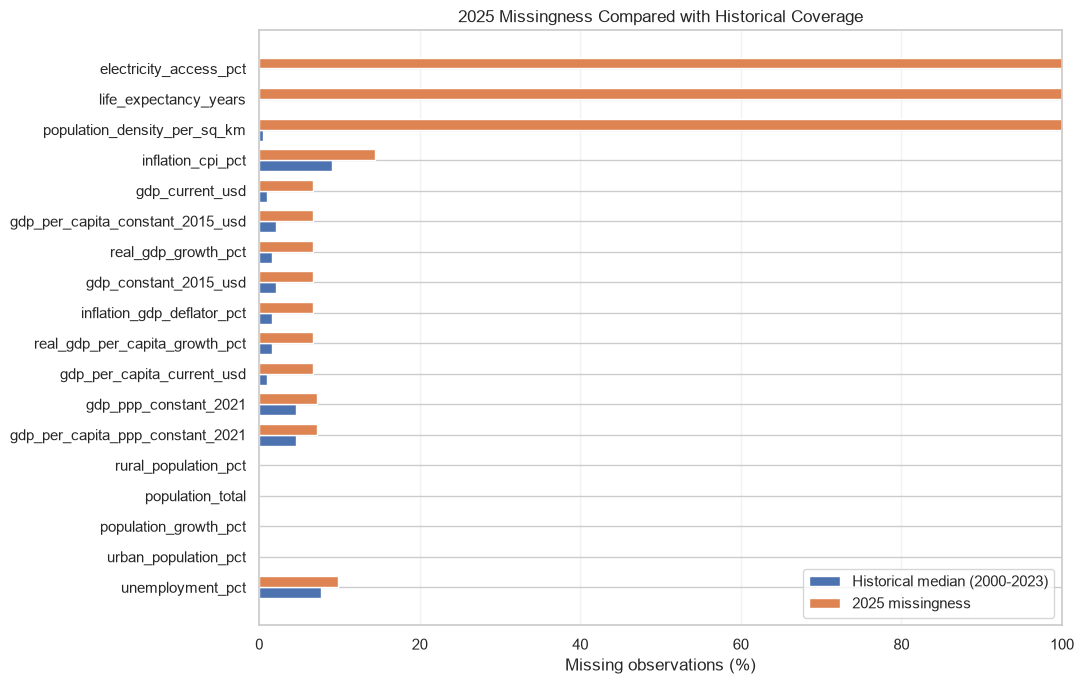

In [51]:
plot_audit = missingness_year_audit.sort_values(
    "change_2025_vs_2024_pp",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

y = np.arange(len(plot_audit))
bar_height = 0.36

ax.barh(
    y - bar_height / 2,
    plot_audit["historical_median_missing_pct_2000_2023"],
    height=bar_height,
    label="Historical median (2000-2023)"
)

ax.barh(
    y + bar_height / 2,
    plot_audit["missing_pct_2025"],
    height=bar_height,
    label="2025 missingness"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_audit.index)
ax.set_xlabel("Missing observations (%)")
ax.set_title("2025 Missingness Compared with Historical Coverage")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### Saving

In [52]:
df_un_core_candidate.info()

<class 'pandas.DataFrame'>
Index: 4940 entries, 0 to 5043
Data columns (total 24 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_iso3_clean                4940 non-null   object 
 1   country_name                      4940 non-null   str    
 2   country_iso2                      4914 non-null   str    
 3   region                            4940 non-null   str    
 4   country_iso3                      4940 non-null   object 
 5   year                              4940 non-null   int64  
 6   gdp_current_usd                   4918 non-null   float64
 7   gdp_per_capita_current_usd        4918 non-null   float64
 8   gdp_constant_2015_usd             4909 non-null   float64
 9   gdp_per_capita_constant_2015_usd  4909 non-null   float64
 10  gdp_ppp_constant_2021             4814 non-null   float64
 11  gdp_per_capita_ppp_constant_2021  4814 non-null   float64
 12  real_gdp_growth_pct   

In [53]:
df_un_core_candidate

,country_iso3_clean,country_name,country_iso2,region,country_iso3,year,gdp_current_usd,gdp_per_capita_current_usd,gdp_constant_2015_usd,gdp_per_capita_constant_2015_usd,gdp_ppp_constant_2021,gdp_per_capita_ppp_constant_2021,real_gdp_growth_pct,real_gdp_per_capita_growth_pct,inflation_cpi_pct,inflation_gdp_deflator_pct,population_total,population_density_per_sq_km,population_growth_pct,urban_population_pct,rural_population_pct,electricity_access_pct,unemployment_pct,life_expectancy_years
0,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",AFG,2000,3.521418e+09,174.930991,6.206548e+09,308.318270,3.256738e+10,1617.826475,NaN,NaN,NaN,NaN,20130327.0,30.863847,1.212176,18.558200,81.441802,4.4,7.897,55.005
1,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",AFG,2001,2.813572e+09,138.706822,5.621148e+09,277.118051,2.949563e+10,1454.110782,-9.431974,-10.119484,NaN,-11.774536,20284307.0,31.099929,0.762005,18.741238,81.258763,9.3,7.973,55.511
2,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",AFG,2002,3.825701e+09,178.954088,7.228796e+09,338.139974,3.793138e+10,1774.308743,28.600001,22.020190,NaN,6.125522,21378117.0,32.776961,5.252030,18.941248,81.058753,14.1,7.867,56.225
3,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",AFG,2003,4.520947e+09,198.871116,7.867263e+09,346.071627,4.128158e+10,1815.928200,8.832278,2.345672,NaN,11.655238,22733049.0,34.854344,6.145194,19.160035,80.839966,19.0,7.844,57.171
4,AFG,Afghanistan,AF,"Middle East, North Africa, Afghanistan & Pakistan",AFG,2004,5.224897e+09,221.763654,7.978516e+09,338.637274,4.186536e+10,1776.918207,1.414118,-2.148212,NaN,11.271432,23560654.0,36.123230,3.575835,19.399359,80.600640,23.8,7.794,57.810
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5039,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,ZWE,2021,4.128785e+10,2613.616741,2.072910e+10,1312.200014,7.625486e+10,4827.109602,8.468017,6.611911,98.546105,108.772817,15797210.0,40.835492,1.726011,37.869206,62.130794,49.0,9.540,60.135
5040,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,ZWE,2022,4.075759e+10,2536.401971,2.200171e+10,1369.197615,8.093635e+10,5036.783177,6.139263,4.343667,104.705171,274.458090,16069056.0,41.538209,1.706209,38.705521,61.294478,50.1,10.087,62.360
5041,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,ZWE,2023,3.587178e+10,2195.225020,2.317900e+10,1418.471846,8.526715e+10,5218.045266,5.350869,3.598767,NaN,768.477178,16340822.0,42.240719,1.677096,39.291937,60.708066,62.0,9.348,62.775
5042,ZWE,Zimbabwe,ZW,Sub-Saharan Africa,ZWE,2024,4.152198e+10,2496.155150,2.356759e+10,1416.800655,8.669665e+10,5211.897556,1.676495,-0.117816,NaN,1097.519784,16634373.0,42.999542,1.780482,39.893372,60.106630,62.0,9.435,63.064


In [54]:
# Cell 59: Recent-year coverage audit

recent_years = [2023, 2024, 2025]

audit_data = df_un_core_candidate.copy()
audit_data["year"] = pd.to_numeric(
    audit_data["year"], errors="coerce"
)

audit_cols = [
    col for col in CORE_INDICATORS
    if col in audit_data.columns
]

audit_rows = []

for col in audit_cols:
    values = pd.to_numeric(audit_data[col], errors="coerce")

    # Latest year with at least one observed value
    observed_years = audit_data.loc[
        values.notna(), "year"
    ]

    latest_observed_year = (
        int(observed_years.max())
        if not observed_years.empty
        else np.nan
    )

    row = {
        "indicator": col,
        "latest_year_with_any_value": latest_observed_year,
    }

    for year in recent_years:
        year_mask = audit_data["year"].eq(year)
        year_values = values.loc[year_mask]
        total = len(year_values)
        missing = int(year_values.isna().sum())

        row[f"missing_{year}"] = missing
        row[f"missing_pct_{year}"] = (
            100 * missing / total if total else np.nan
        )
        row[f"available_{year}"] = total - missing

    audit_rows.append(row)

recent_coverage_audit = (
    pd.DataFrame(audit_rows)
    .sort_values("missing_pct_2025", ascending=False)
)

display(recent_coverage_audit.round(2))

,indicator,latest_year_with_any_value,missing_2023,missing_pct_2023,available_2023,missing_2024,missing_pct_2024,available_2024,missing_2025,missing_pct_2025,available_2025
17,life_expectancy_years,2024,0,0.00,190,0,0.00,190,190,100.00,0
15,electricity_access_pct,2024,0,0.00,190,0,0.00,190,190,100.00,0
11,population_density_per_sq_km,2024,0,0.00,190,1,0.53,189,190,100.00,0
8,inflation_cpi_pct,2025,17,8.95,173,18,9.47,172,24,12.63,166
16,unemployment_pct,2025,16,8.42,174,17,8.95,173,17,8.95,173
5,gdp_per_capita_ppp_constant_2021,2025,5,2.63,185,6,3.16,184,10,5.26,180
4,gdp_ppp_constant_2021,2025,5,2.63,185,6,3.16,184,10,5.26,180
0,gdp_current_usd,2025,3,1.58,187,4,2.11,186,9,4.74,181
1,gdp_per_capita_current_usd,2025,3,1.58,187,4,2.11,186,9,4.74,181
3,gdp_per_capita_constant_2015_usd,2025,2,1.05,188,3,1.58,187,9,4.74,181


In [55]:
# Focus on the three indicators with 100% missingness in 2025
endpoint_indicators = [
    "electricity_access_pct",
    "life_expectancy_years",
    "population_density_per_sq_km",
]

endpoint_indicators = [
    col for col in endpoint_indicators
    if col in audit_data.columns
]

for col in endpoint_indicators:
    print(f"\n{col}")

    available_by_year = (
        audit_data.groupby("year")[col]
        .agg(
            available_count="count",
            median="median",
        )
        .reindex(range(2020, 2026))
    )

    display(available_by_year.round(2))

    # Show countries with an observation in 2024 but none in 2025
    value_2024 = audit_data.loc[
        audit_data["year"].eq(2024),
        ["country_iso3_clean", "country_name", col]
    ].set_index("country_iso3_clean")[col]

    value_2025 = audit_data.loc[
        audit_data["year"].eq(2025),
        ["country_iso3_clean", col]
    ].set_index("country_iso3_clean")[col]

    previously_available = value_2024.notna()
    missing_in_2025 = value_2025.isna()

    affected_codes = value_2024.index[
        previously_available
        & missing_in_2025.reindex(
            value_2024.index, fill_value=True
        )
    ]

    print(
        "Countries with a 2024 value but no 2025 value:",
        len(affected_codes)
    )


electricity_access_pct


,available_count,median
year,,
2020,190,99.9
2021,190,100.0
2022,190,100.0
2023,190,100.0
2024,190,100.0
2025,0,NaN


Countries with a 2024 value but no 2025 value: 190

life_expectancy_years


,available_count,median
year,,
2020,190,72.28
2021,190,71.57
2022,190,73.29
2023,190,73.60
2024,190,73.83
2025,0,NaN


Countries with a 2024 value but no 2025 value: 190

population_density_per_sq_km


,available_count,median
year,,
2020,190,88.19
2021,190,89.52
2022,190,88.58
2023,190,87.55
2024,189,87.80
2025,0,NaN


Countries with a 2024 value but no 2025 value: 189


In [56]:
# Save the pre-imputation candidate dataset
SEMICLEANED_DIR = INTERIM_DIR / "worldbank_semicleaned_wide"
SEMICLEANED_DIR.mkdir(parents=True, exist_ok=True)

output_path = SEMICLEANED_DIR / "worldbank_un_cleaned.csv"

df_un_core_candidate.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Shape:", df_un_core_candidate.shape)
print(
    "Unique entities:",
    df_un_core_candidate["country_iso3_clean"].nunique()
)


Saved: d:\DA2402\Project\EarthQuake\data\interim\worldbank_semicleaned_wide\worldbank_un_cleaned.csv
Shape: (4940, 24)
Unique entities: 190


In [57]:
# Export the full 194-entity panel and other World Bank data

SEMICLEANED_DIR = INTERIM_DIR / "worldbank_semicleaned_wide"
SEMICLEANED_DIR.mkdir(parents=True, exist_ok=True)

# 1. Full panel: 193 UN member states + Hong Kong
worldbank_194 = complete_panel.copy()

worldbank_194.to_csv(
    SEMICLEANED_DIR / "worldbank_un.csv",
    index=False
)

print(
    "worldbank_194.csv:",
    worldbank_194.shape,
    "entities:",
    worldbank_194["country_iso3_clean"].nunique()
)

# 2. Other non-UN entities and territories, including Hong Kong
source = wb_classified.copy()

source["year"] = pd.to_numeric(source["year"], errors="coerce")
source["country_iso3_clean"] = (
    source["country_iso3"]
    .astype("string")
    .str.strip()
    .str.upper()
)

TRUE_UN_ISO3 = set(UN_MEMBER_ISO3) - {"HKG"}

source = source.loc[
    source["year"].between(2000, 2025)
].copy()

is_aggregate = source["entity_type"].eq("World Bank aggregate")
has_iso3 = (
    source["country_iso3_clean"].notna()
    & source["country_iso3_clean"].ne("")
)

non_un_mask = (
    ~is_aggregate
    & has_iso3
    & ~source["country_iso3_clean"].isin(TRUE_UN_ISO3)
)

worldbank_non_un = source.loc[non_un_mask].copy()

worldbank_non_un.to_csv(
    SEMICLEANED_DIR / "worldbank_non_un.csv",
    index=False
)

print(
    "worldbank_non_un.csv:",
    worldbank_non_un.shape,
    "entities:",
    worldbank_non_un["country_iso3_clean"].nunique()
)

# 3. World Bank regional, income-group and global aggregates
worldbank_agg = source.loc[is_aggregate].copy()

worldbank_agg.to_csv(
    SEMICLEANED_DIR / "worldbank_agg.csv",
    index=False
)

print(
    "worldbank_agg.csv:",
    worldbank_agg.shape,
    "entities:",
    worldbank_agg["country_iso3_clean"].nunique()
)

print("\nSaved all files to:", SEMICLEANED_DIR)

worldbank_194.csv: (5044, 24) entities: 194
worldbank_non_un.csv: (624, 40) entities: 24
worldbank_agg.csv: (1274, 40) entities: 49

Saved all files to: d:\DA2402\Project\EarthQuake\data\interim\worldbank_semicleaned_wide
